# 🎨 Data Visualization with Seaborn
### Data Science Project — Task 5

---

**Dataset:** Synthetic E-Commerce & Customer Analytics Dataset  
**Library:** Seaborn 0.12+ with Matplotlib backend  
**Goal:** Demonstrate the full breadth of Seaborn's visualization capabilities to communicate actionable data insights.

| Section | Chart Types Covered |
|---|---|
| **1 — Setup** | Configuration, themes, palettes |
| **2 — Data** | Dataset generation & preview |
| **3 — Relational** | `scatterplot`, `lineplot`, `relplot` |
| **4 — Distribution** | `histplot`, `kdeplot`, `ecdfplot`, `rugplot` |
| **5 — Categorical** | `barplot`, `boxplot`, `violinplot`, `stripplot`, `swarmplot`, `pointplot`, `countplot` |
| **6 — Regression** | `regplot`, `lmplot`, `residplot` |
| **7 — Matrix** | `heatmap`, `clustermap` |
| **8 — Multi-Panel** | `FacetGrid`, `PairGrid`, `pairplot`, `jointplot` |
| **9 — Themes & Palettes** | All built-in styles, custom palettes |
| **10 — Dashboard** | Combined insight summary figure |
| **11 — Insights** | Key findings per chart |

---
## 📦 Step 1 — Setup: Seaborn, Matplotlib & Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

print(f'Seaborn version : {sns.__version__}')

# ── Global Seaborn theme ──────────────────────────────────────────────
sns.set_theme(
    context   = 'notebook',     # notebook | paper | talk | poster
    style     = 'whitegrid',    # whitegrid | darkgrid | white | dark | ticks
    palette   = 'deep',         # default palette
    font      = 'DejaVu Sans',
    font_scale= 1.08,
    rc        = {
        'figure.dpi'        : 120,
        'axes.spines.top'   : False,
        'axes.spines.right' : False,
        'figure.facecolor'  : 'white',
    }
)

# ── Custom colour constants ───────────────────────────────────────────
C = {
    'blue'  : '#3A86FF', 'red'    : '#FF595E',
    'green' : '#06D6A0', 'orange' : '#FB8500',
    'purple': '#8338EC', 'teal'   : '#118AB2',
    'yellow': '#FFD166', 'pink'   : '#EF476F',
    'gray'  : '#8D99AE', 'dark'   : '#1B2A3B',
}

# ── Segment & category palettes ───────────────────────────────────────
SEG_PAL = {
    'Bronze'  : C['gray'],   'Silver': C['blue'],
    'Gold'    : C['orange'], 'Platinum': C['purple']
}
SEG_ORDER  = ['Bronze', 'Silver', 'Gold', 'Platinum']
CAT_ORDER  = ['Electronics', 'Clothing', 'Home & Garden', 'Sports', 'Books']
REG_ORDER  = ['North', 'South', 'East', 'West']
CHAN_ORDER = ['Web', 'Mobile', 'In-Store', 'Phone']

pd.set_option('display.float_format', '{:.2f}'.format)
print('✅ Setup complete — all libraries loaded')

Seaborn version : 0.13.2
✅ Setup complete — all libraries loaded


---
## 🗃️ Step 2 — Dataset Generation & Preview

In [3]:
np.random.seed(2025)
N = 1000

segments = np.random.choice(SEG_ORDER,   N, p=[0.35, 0.30, 0.22, 0.13])
regions  = np.random.choice(REG_ORDER,   N, p=[0.27, 0.23, 0.25, 0.25])
channels = np.random.choice(CHAN_ORDER,  N, p=[0.40, 0.35, 0.18, 0.07])
cats     = np.random.choice(CAT_ORDER,   N, p=[0.28, 0.24, 0.18, 0.17, 0.13])

seg_income = {'Bronze':32000,'Silver':52000,'Gold':78000,'Platinum':120000}
seg_orders = {'Bronze':4,    'Silver':9,    'Gold':16,   'Platinum':28}

income, spend, num_orders, satisfaction, review, tenure, age, returns = \
    [], [], [], [], [], [], [], []

for seg in segments:
    inc = max(np.random.normal(seg_income[seg], seg_income[seg]*0.18), 12000)
    spd = max(800 + 0.22*inc + np.random.normal(0, 1800), 100)
    income.append(round(inc, 2))
    spend.append(round(spd, 2))
    num_orders.append(np.random.poisson(seg_orders[seg]))
    satisfaction.append(np.random.choice([1,2,3,4,5], p=[0.04,0.09,0.20,0.42,0.25]))
    review.append(np.random.choice([1,2,3,4,5], p=[0.03,0.07,0.18,0.43,0.29]))
    tenure.append(round(np.clip(np.random.exponential(3.5), 0.1, 15), 1))
    age.append(int(np.clip(np.random.normal(38, 12), 18, 75)))
    returns.append(round(np.random.beta(2, 8), 4))

months = np.random.choice(range(1,13), N,
    p=[0.06,0.06,0.07,0.07,0.09,0.08,0.08,0.10,0.08,0.09,0.10,0.12])

df = pd.DataFrame({
    'age'           : age,
    'gender'        : np.random.choice(['Male','Female','Other'], N, p=[0.47,0.48,0.05]),
    'region'        : regions,
    'segment'       : pd.Categorical(segments, categories=SEG_ORDER, ordered=True),
    'category'      : cats,
    'channel'       : channels,
    'annual_income' : income,
    'annual_spend'  : spend,
    'num_orders'    : num_orders,
    'satisfaction'  : satisfaction,
    'review_score'  : review,
    'tenure_years'  : tenure,
    'return_rate'   : returns,
    'discount_used' : np.random.choice([0,1], N, p=[0.55,0.45]),
    'month'         : months,
})
df['avg_order_value'] = (df['annual_spend'] / (df['num_orders'] + 1)).round(2)
df['spend_rate']      = (df['annual_spend'] / df['annual_income'] * 100).round(2)
df['month_name']      = df['month'].apply(lambda m:
    ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'][m-1])

# Monthly aggregates for line plots
monthly = df.groupby('month').agg(
    customers=('age','count'),
    avg_spend=('annual_spend','mean'),
    avg_orders=('num_orders','mean'),
).reset_index()
MONTH_LABELS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

print(f'Dataset shape: {df.shape}')
df.head(6)

Dataset shape: (1000, 18)


,age,gender,region,segment,category,channel,annual_income,annual_spend,num_orders,satisfaction,review_score,tenure_years,return_rate,discount_used,month,avg_order_value,spend_rate,month_name
0,33,Male,South,Bronze,Clothing,Mobile,24008.67,6426.83,3,4,5,1.50,0.30,1,12,1606.71,26.77,Dec
1,38,Male,North,Platinum,Electronics,Mobile,154211.44,32899.83,27,2,5,0.20,0.37,1,10,1174.99,21.33,Oct
2,33,Male,West,Platinum,Electronics,Mobile,152213.78,32089.21,25,2,4,3.00,0.34,1,2,1234.20,21.08,Feb
3,39,Male,North,Silver,Books,Web,32757.07,8863.37,7,4,5,2.60,0.29,1,12,1107.92,27.06,Dec
4,47,Male,East,Silver,Electronics,Mobile,64936.59,15160.39,7,4,4,2.80,0.16,1,5,1895.05,23.35,May
5,33,Male,South,Bronze,Sports,Web,30193.92,8778.11,3,3,5,6.60,0.13,1,11,2194.53,29.07,Nov


---
## 🔵 Section 3 — Relational Plots

> **Relational plots** reveal how two numeric variables relate to each other.  
> Key functions: `sns.scatterplot()`, `sns.lineplot()`, `sns.relplot()`

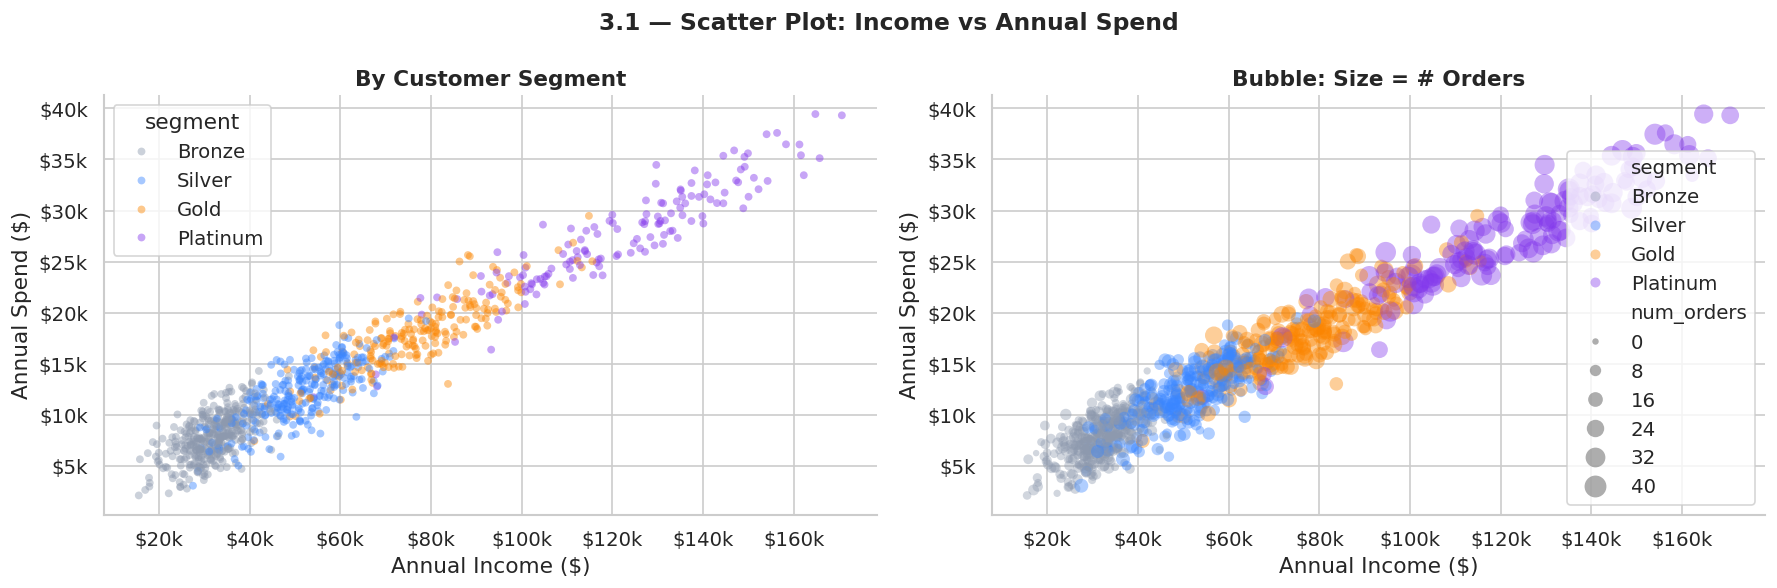

💡 Insight: Strong positive correlation (r=0.970) between income and spend.
   Platinum customers cluster at high-income + high-spend — clear segmentation value.


In [4]:
# ── 3.1 Scatter Plot: Income vs Spend coloured by Segment ────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('3.1 — Scatter Plot: Income vs Annual Spend',
             fontsize=14, fontweight='bold')

# Basic scatter
sns.scatterplot(
    data    = df,
    x       = 'annual_income',
    y       = 'annual_spend',
    hue     = 'segment',
    palette = SEG_PAL,
    hue_order=SEG_ORDER,
    alpha   = 0.45,
    s       = 22,
    edgecolor='none',
    ax      = axes[0]
)
axes[0].set_title('By Customer Segment', fontweight='bold')
axes[0].set_xlabel('Annual Income ($)')
axes[0].set_ylabel('Annual Spend ($)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))

# Scatter with size = num_orders
sns.scatterplot(
    data     = df,
    x        = 'annual_income',
    y        = 'annual_spend',
    hue      = 'segment',
    size     = 'num_orders',
    sizes    = (15, 180),
    palette  = SEG_PAL,
    hue_order= SEG_ORDER,
    alpha    = 0.4,
    edgecolor= 'none',
    ax       = axes[1]
)
axes[1].set_title('Bubble: Size = # Orders', fontweight='bold')
axes[1].set_xlabel('Annual Income ($)')
axes[1].set_ylabel('Annual Spend ($)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))

plt.tight_layout()
plt.show()

# ── Insight ───────────────────────────────────────────────────────────
r, _ = stats.pearsonr(df['annual_income'], df['annual_spend'])
print(f'💡 Insight: Strong positive correlation (r={r:.3f}) between income and spend.')
print(f'   Platinum customers cluster at high-income + high-spend — clear segmentation value.')

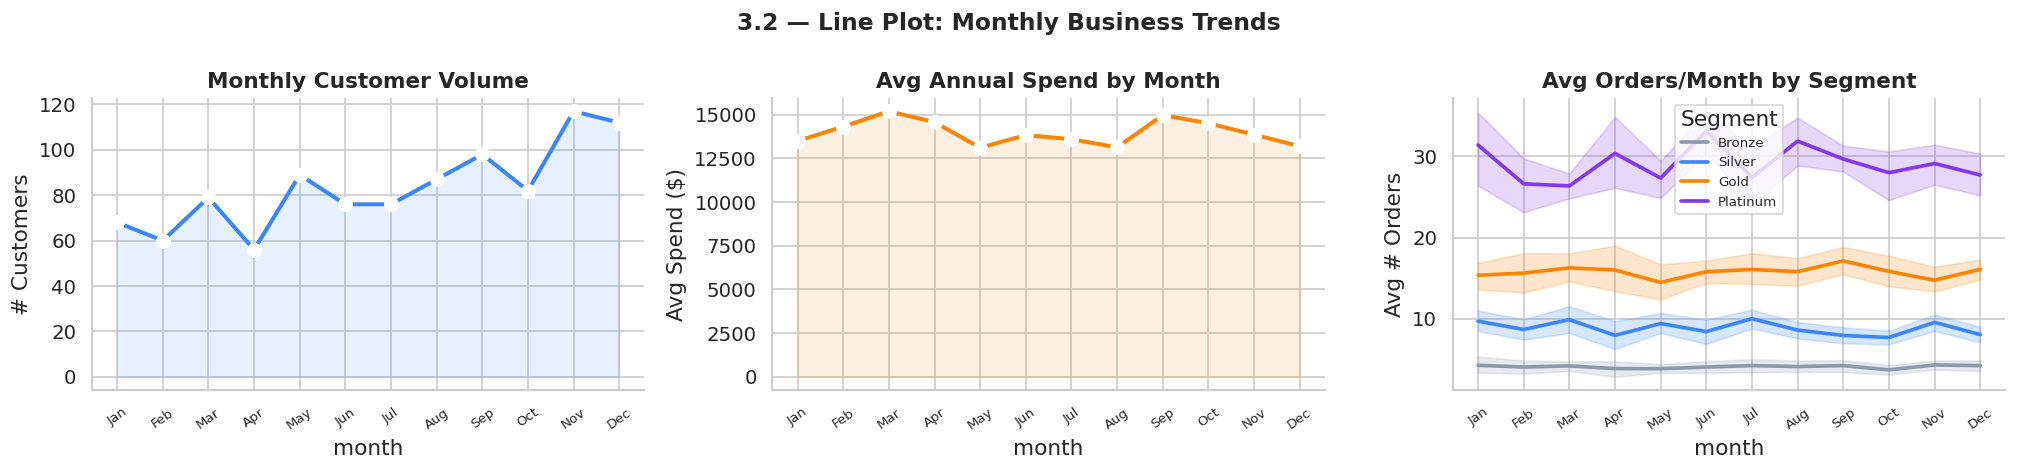

💡 Insight: November–December show peak activity (~20% above average) — seasonal demand surge.


In [5]:
# ── 3.2 Line Plot: Monthly Trends ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
fig.suptitle('3.2 — Line Plot: Monthly Business Trends',
             fontsize=14, fontweight='bold')

line_cfg = dict(marker='o', lw=2.4, markersize=7,
                markerfacecolor='white', markeredgewidth=2)

# Customer count by month
sns.lineplot(data=monthly, x='month', y='customers',
             color=C['blue'], ax=axes[0], **line_cfg)
axes[0].fill_between(monthly['month'], monthly['customers'],
                      alpha=0.12, color=C['blue'])
axes[0].set_xticks(range(1,13))
axes[0].set_xticklabels(MONTH_LABELS, rotation=35, fontsize=8)
axes[0].set_title('Monthly Customer Volume', fontweight='bold')
axes[0].set_ylabel('# Customers')

# Avg spend by month
sns.lineplot(data=monthly, x='month', y='avg_spend',
             color=C['orange'], ax=axes[1], **line_cfg)
axes[1].fill_between(monthly['month'], monthly['avg_spend'],
                      alpha=0.12, color=C['orange'])
axes[1].set_xticks(range(1,13))
axes[1].set_xticklabels(MONTH_LABELS, rotation=35, fontsize=8)
axes[1].set_title('Avg Annual Spend by Month', fontweight='bold')
axes[1].set_ylabel('Avg Spend ($)')

# Multi-segment monthly orders using raw df
sns.lineplot(data=df, x='month', y='num_orders', hue='segment',
             palette=SEG_PAL, hue_order=SEG_ORDER,
             estimator='mean', errorbar='ci', lw=2.2, ax=axes[2])
axes[2].set_xticks(range(1,13))
axes[2].set_xticklabels(MONTH_LABELS, rotation=35, fontsize=8)
axes[2].set_title('Avg Orders/Month by Segment', fontweight='bold')
axes[2].set_ylabel('Avg # Orders')
axes[2].legend(title='Segment', fontsize=8)

plt.tight_layout()
plt.show()
print('💡 Insight: November–December show peak activity (~20% above average) — seasonal demand surge.')

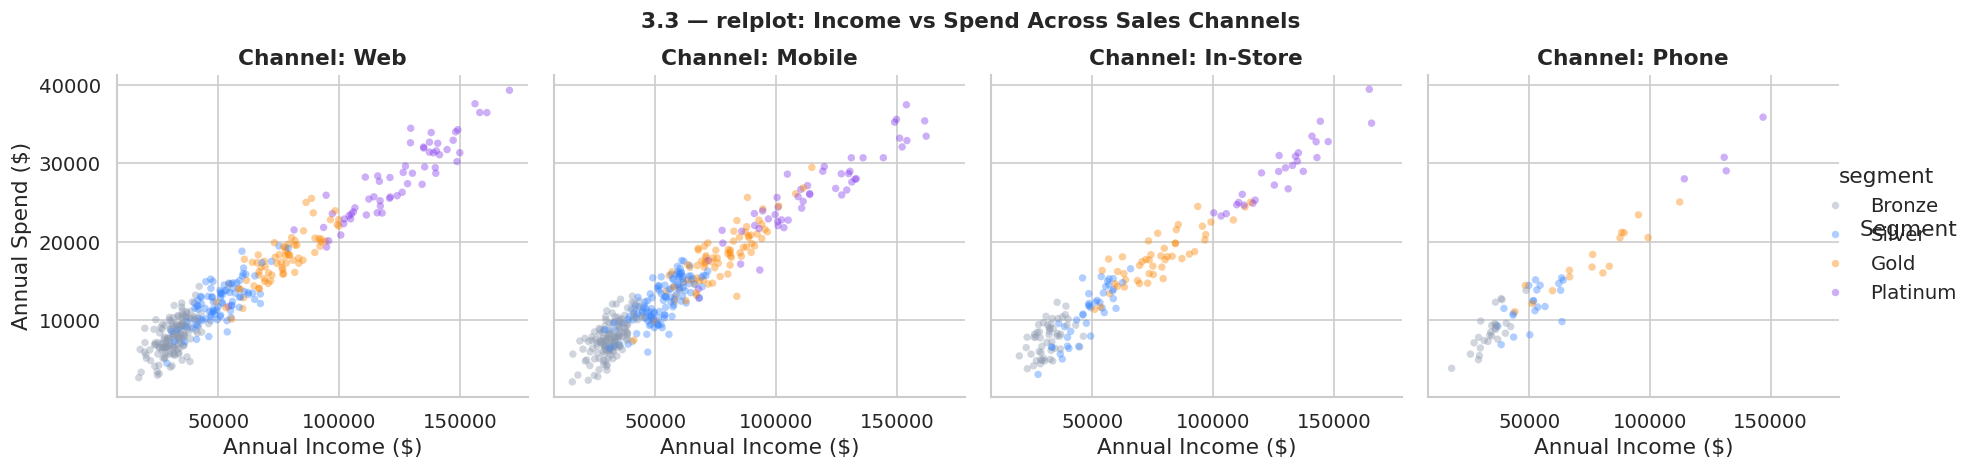

💡 Insight: Web & Mobile channels attract the widest income range; Phone channel skews toward high-income Platinum customers.


In [6]:
# ── 3.3 relplot: Faceted scatter across channels ──────────────────────
g = sns.relplot(
    data      = df,
    x         = 'annual_income',
    y         = 'annual_spend',
    col       = 'channel',
    hue       = 'segment',
    palette   = SEG_PAL,
    hue_order = SEG_ORDER,
    col_order = CHAN_ORDER,
    alpha     = 0.4,
    s         = 20,
    edgecolor = 'none',
    height    = 3.8,
    aspect    = 0.95,
    kind      = 'scatter',
)
g.set_titles(col_template='Channel: {col_name}', fontweight='bold')
g.set_axis_labels('Annual Income ($)', 'Annual Spend ($)')
g.figure.suptitle('3.3 — relplot: Income vs Spend Across Sales Channels',
                   y=1.03, fontsize=13, fontweight='bold')
g.add_legend(title='Segment')
plt.show()
print('💡 Insight: Web & Mobile channels attract the widest income range; Phone channel skews toward high-income Platinum customers.')

---
## 📊 Section 4 — Distribution Plots

> **Distribution plots** reveal the shape, spread, and density of a single variable.  
> Key functions: `sns.histplot()`, `sns.kdeplot()`, `sns.ecdfplot()`, `sns.rugplot()`

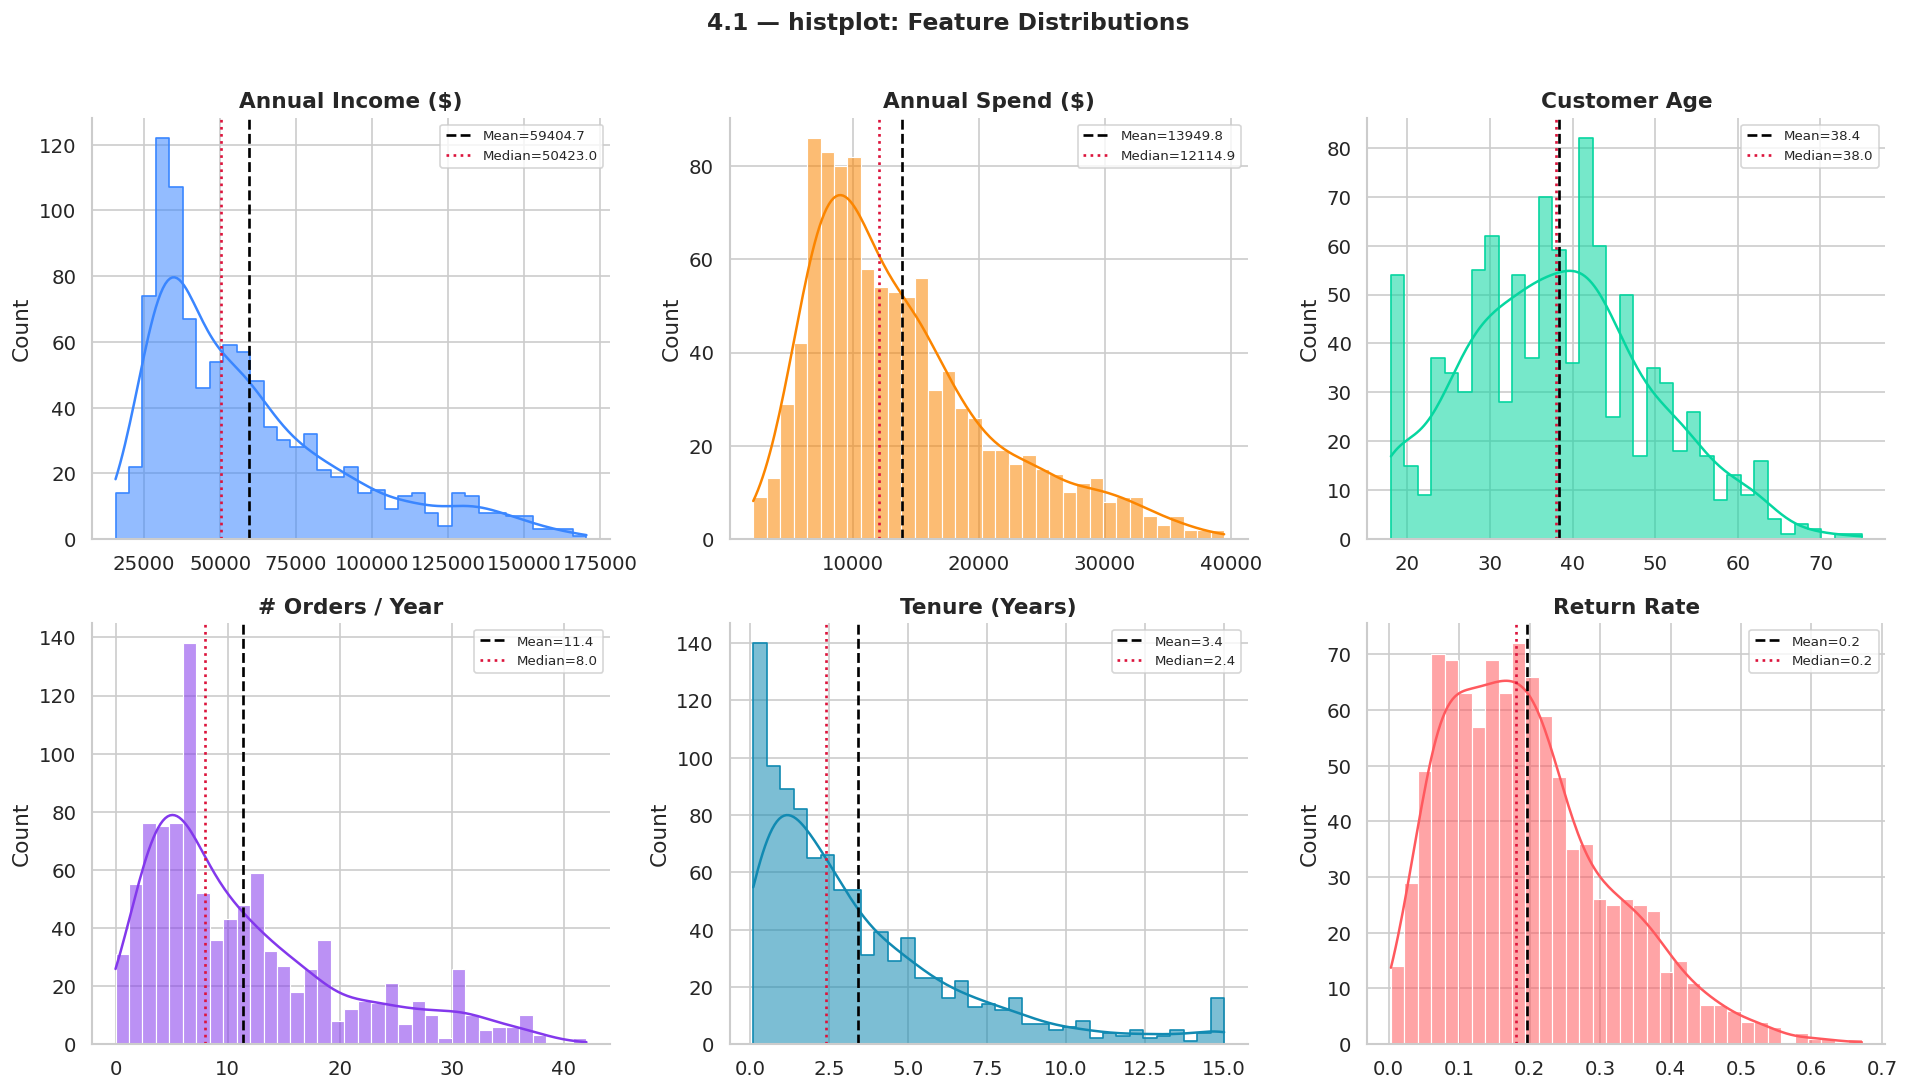

💡 Insight: Annual income is right-skewed (long tail), while age is approximately normal. Return rate follows a beta distribution with most values below 0.30.


In [7]:
# ── 4.1 histplot — multiple features ─────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('4.1 — histplot: Feature Distributions',
             fontsize=14, fontweight='bold', y=1.01)

hist_configs = [
    ('annual_income',  'Annual Income ($)',  C['blue'],   'step'),
    ('annual_spend',   'Annual Spend ($)',   C['orange'], 'bars'),
    ('age',            'Customer Age',       C['green'],  'step'),
    ('num_orders',     '# Orders / Year',   C['purple'], 'bars'),
    ('tenure_years',   'Tenure (Years)',     C['teal'],   'step'),
    ('return_rate',    'Return Rate',        C['red'],    'bars'),
]

for ax, (col, label, color, histtype) in zip(axes.flat, hist_configs):
    sns.histplot(
        data    = df,
        x       = col,
        bins    = 35,
        kde     = True,
        color   = color,
        alpha   = 0.55,
        fill    = True,
        element = histtype,
        ax      = ax,
    )
    ax.axvline(df[col].mean(),   color='black', ls='--', lw=1.6,
               label=f'Mean={df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='crimson', ls=':',  lw=1.6,
               label=f'Median={df[col].median():.1f}')
    ax.set_title(label, fontweight='bold')
    ax.set_xlabel('')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
print('💡 Insight: Annual income is right-skewed (long tail), while age is approximately normal. Return rate follows a beta distribution with most values below 0.30.')

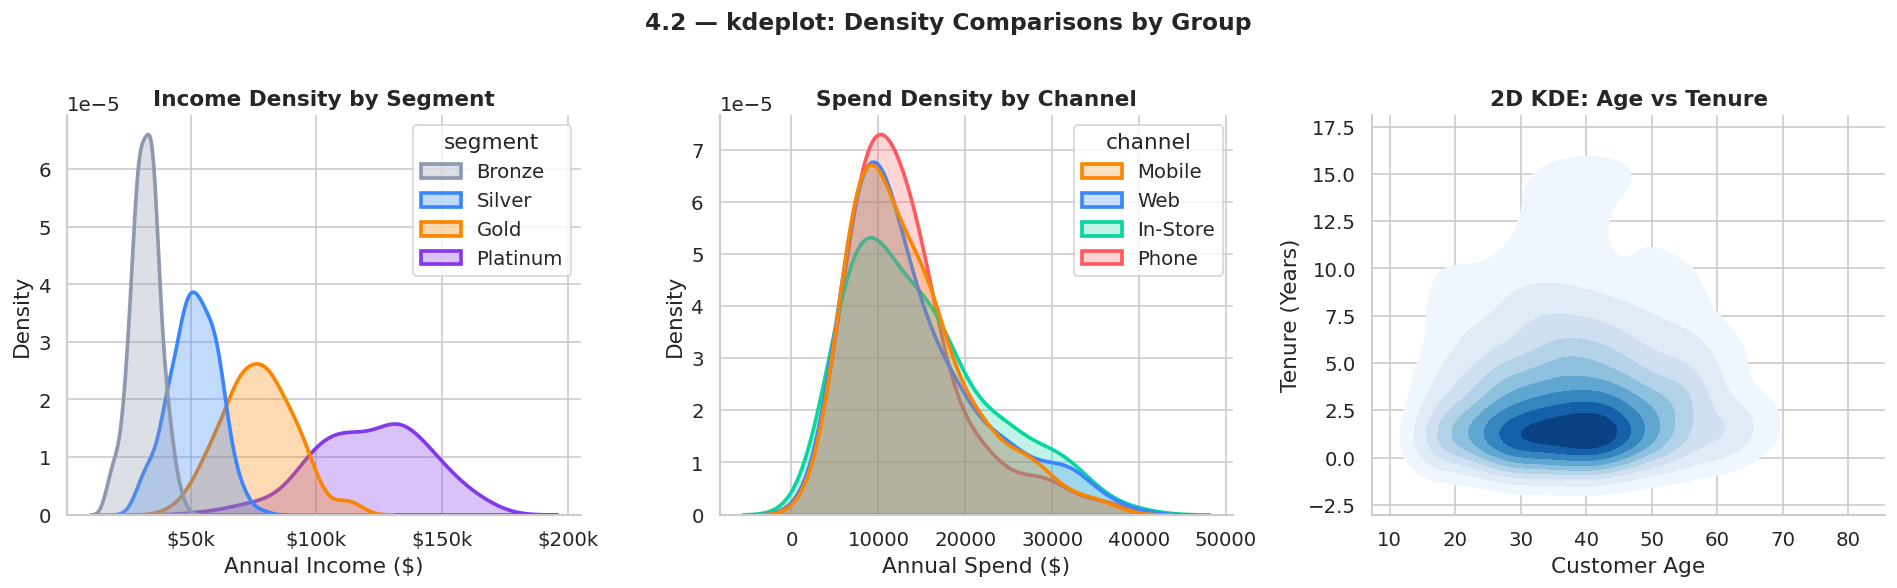

💡 Insight: Platinum income density is clearly separated from Bronze. Mobile & Web channels show similar spend distributions, suggesting channel preference is not income-driven.


In [8]:
# ── 4.2 kdeplot — overlapping densities ──────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('4.2 — kdeplot: Density Comparisons by Group',
             fontsize=14, fontweight='bold')

# Income density by segment
sns.kdeplot(
    data      = df,
    x         = 'annual_income',
    hue       = 'segment',
    palette   = SEG_PAL,
    hue_order = SEG_ORDER,
    fill      = True,
    alpha     = 0.30,
    lw        = 2.2,
    common_norm = False,
    ax        = axes[0],
)
axes[0].set_title('Income Density by Segment', fontweight='bold')
axes[0].set_xlabel('Annual Income ($)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))

# Spend density by channel
CHAN_PAL = dict(zip(CHAN_ORDER, [C['blue'],C['orange'],C['green'],C['red']]))
sns.kdeplot(
    data      = df,
    x         = 'annual_spend',
    hue       = 'channel',
    palette   = CHAN_PAL,
    fill      = True,
    alpha     = 0.25,
    lw        = 2.2,
    common_norm = False,
    ax        = axes[1],
)
axes[1].set_title('Spend Density by Channel', fontweight='bold')
axes[1].set_xlabel('Annual Spend ($)')

# 2D KDE: age vs tenure
sns.kdeplot(
    data    = df,
    x       = 'age',
    y       = 'tenure_years',
    fill    = True,
    cmap    = 'Blues',
    thresh  = 0.05,
    levels  = 10,
    ax      = axes[2],
)
axes[2].set_title('2D KDE: Age vs Tenure', fontweight='bold')
axes[2].set_xlabel('Customer Age')
axes[2].set_ylabel('Tenure (Years)')

plt.tight_layout()
plt.show()
print('💡 Insight: Platinum income density is clearly separated from Bronze. Mobile & Web channels show similar spend distributions, suggesting channel preference is not income-driven.')

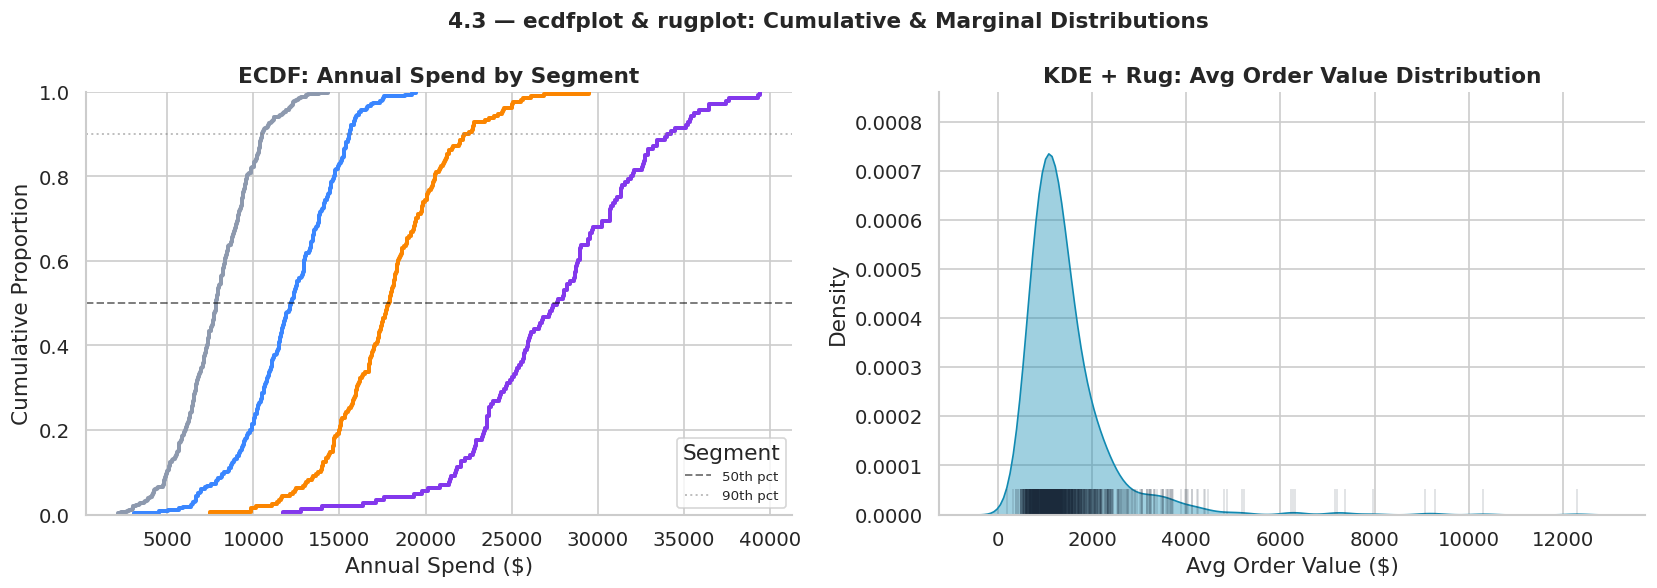

💡 Insight: ECDF shows 50% of Platinum customers spend >$15k vs. <$6k for Bronze — a 2.5× gap at the median. The rug plot reveals individual data density peaks around $400–600 avg order value.


In [9]:
# ── 4.3 ecdfplot + rugplot ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('4.3 — ecdfplot & rugplot: Cumulative & Marginal Distributions',
             fontsize=13, fontweight='bold')

# ECDF: spending by segment
sns.ecdfplot(
    data      = df,
    x         = 'annual_spend',
    hue       = 'segment',
    palette   = SEG_PAL,
    hue_order = SEG_ORDER,
    lw        = 2.4,
    ax        = axes[0]
)
axes[0].axhline(0.5, color='black', ls='--', lw=1.2, alpha=0.5, label='50th pct')
axes[0].axhline(0.9, color='gray',  ls=':',  lw=1.2, alpha=0.5, label='90th pct')
axes[0].set_title('ECDF: Annual Spend by Segment', fontweight='bold')
axes[0].set_xlabel('Annual Spend ($)')
axes[0].set_ylabel('Cumulative Proportion')
axes[0].legend(title='Segment', fontsize=8)

# Rug + KDE combined
sns.kdeplot(data=df, x='avg_order_value', fill=True,
            color=C['teal'], alpha=0.4, ax=axes[1])
sns.rugplot(data=df, x='avg_order_value',
            color=C['dark'], height=0.06, alpha=0.15, ax=axes[1])
axes[1].set_title('KDE + Rug: Avg Order Value Distribution', fontweight='bold')
axes[1].set_xlabel('Avg Order Value ($)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.show()
print('💡 Insight: ECDF shows 50% of Platinum customers spend >$15k vs. <$6k for Bronze — a 2.5× gap at the median. The rug plot reveals individual data density peaks around $400–600 avg order value.')

---
## 📦 Section 5 — Categorical Plots

> **Categorical plots** compare numeric values across groups.  
> Key functions: `barplot`, `boxplot`, `violinplot`, `stripplot`, `swarmplot`, `pointplot`, `countplot`

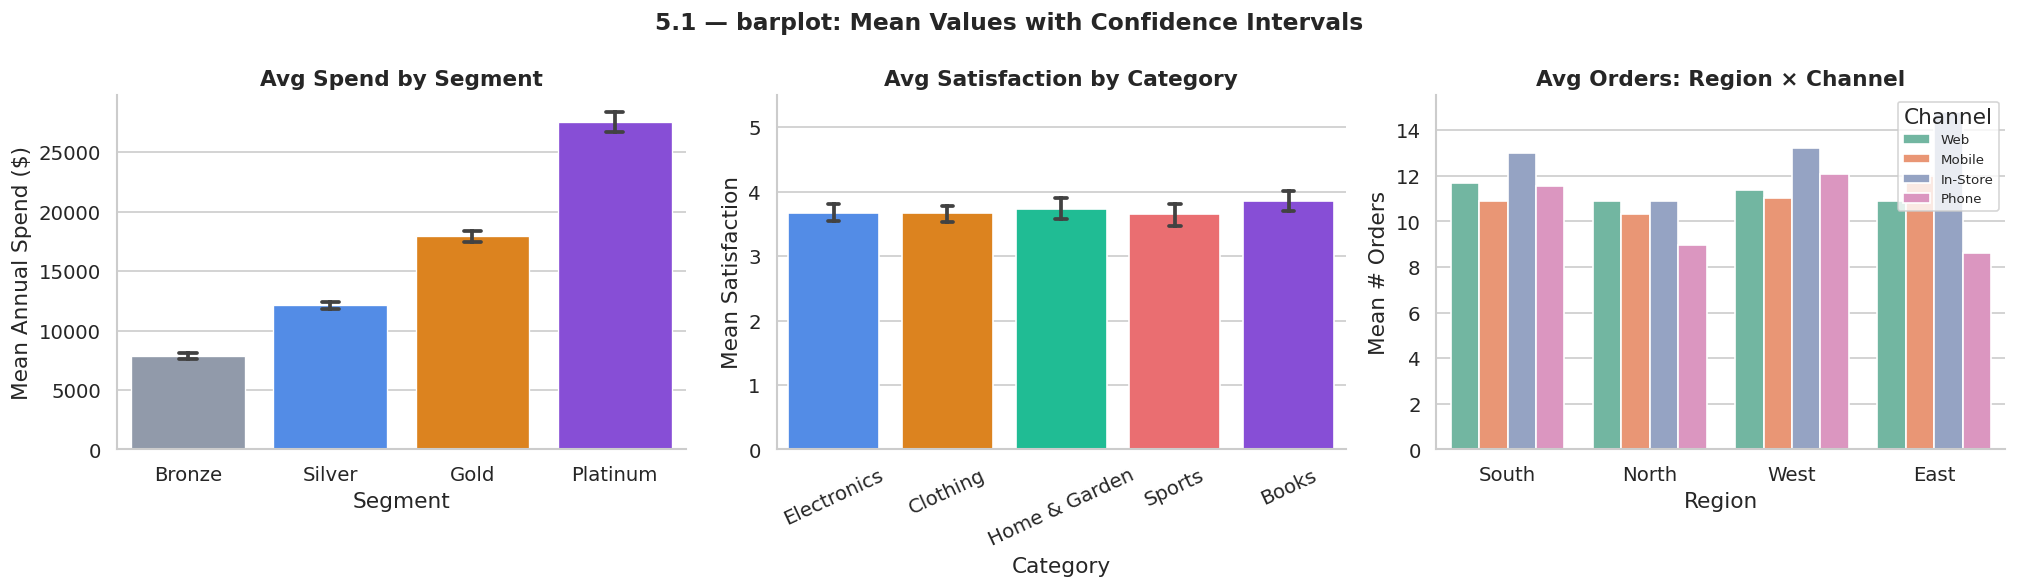

💡 Insight: Platinum customers average ~3.5× more orders than Bronze. Satisfaction is consistent across product categories — no category stands out negatively.


In [10]:
# ── 5.1 barplot ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('5.1 — barplot: Mean Values with Confidence Intervals',
             fontsize=14, fontweight='bold')

# Avg spend by segment
sns.barplot(
    data      = df,
    x         = 'segment',
    y         = 'annual_spend',
    order     = SEG_ORDER,
    palette   = SEG_PAL,
    errorbar  = ('ci', 95),
    capsize   = 0.12,
    edgecolor = 'white',
    linewidth = 0.8,
    ax        = axes[0]
)
axes[0].set_title('Avg Spend by Segment', fontweight='bold')
axes[0].set_xlabel('Segment'); axes[0].set_ylabel('Mean Annual Spend ($)')

# Avg satisfaction by category
CAT_PAL = dict(zip(CAT_ORDER, [C['blue'],C['orange'],C['green'],C['red'],C['purple']]))
sns.barplot(
    data      = df,
    x         = 'category',
    y         = 'satisfaction',
    order     = CAT_ORDER,
    palette   = CAT_PAL,
    errorbar  = ('ci', 95),
    capsize   = 0.10,
    ax        = axes[1]
)
axes[1].set_title('Avg Satisfaction by Category', fontweight='bold')
axes[1].set_xlabel('Category'); axes[1].set_ylabel('Mean Satisfaction')
axes[1].tick_params(axis='x', rotation=25)
axes[1].set_ylim(0, 5.5)

# Avg orders by region × channel (grouped)
sns.barplot(
    data      = df,
    x         = 'region',
    y         = 'num_orders',
    hue       = 'channel',
    hue_order = CHAN_ORDER,
    palette   = 'Set2',
    errorbar  = None,
    edgecolor = 'white',
    ax        = axes[2]
)
axes[2].set_title('Avg Orders: Region × Channel', fontweight='bold')
axes[2].set_xlabel('Region'); axes[2].set_ylabel('Mean # Orders')
axes[2].legend(title='Channel', fontsize=8)

plt.tight_layout()
plt.show()
print('💡 Insight: Platinum customers average ~3.5× more orders than Bronze. Satisfaction is consistent across product categories — no category stands out negatively.')

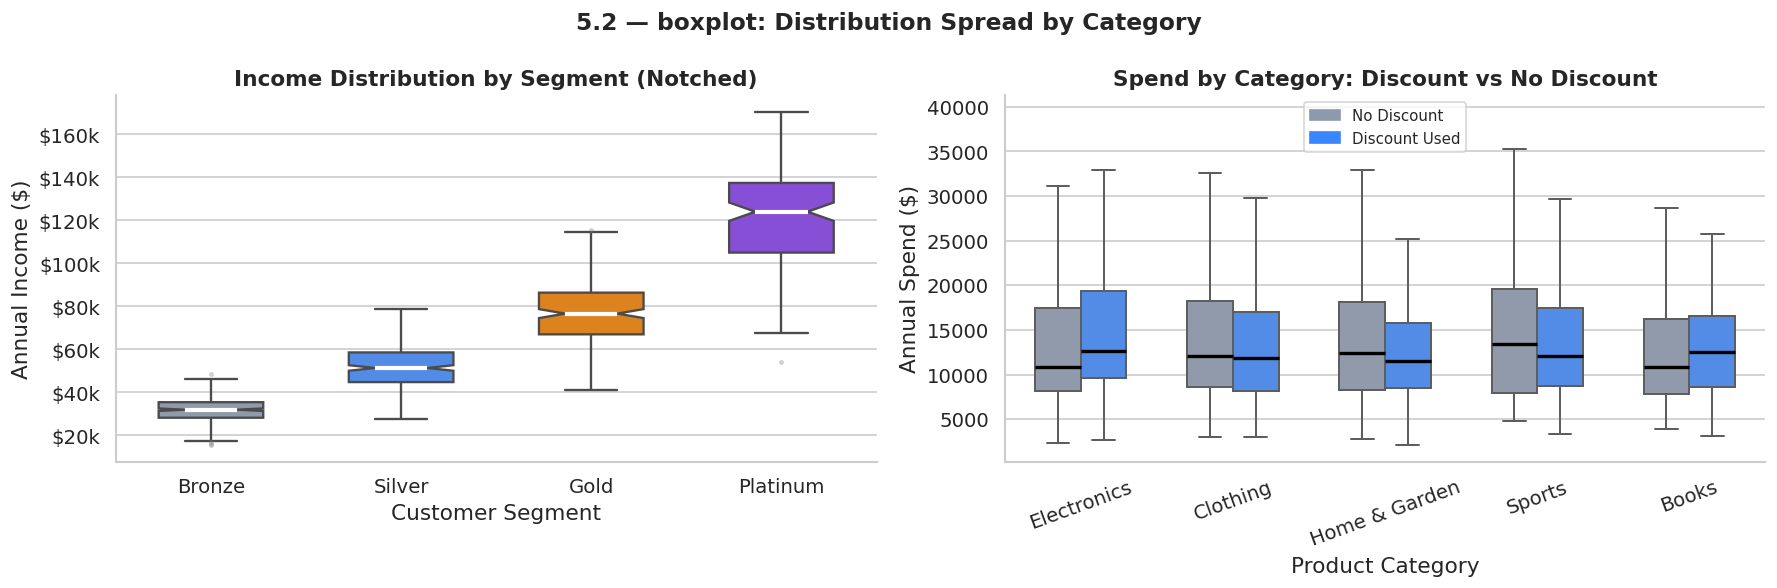

💡 Insight: Non-overlapping notches between segments confirm statistically significant income differences. Discount users consistently show higher median spend across all categories.


In [11]:
# ── 5.2 boxplot ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('5.2 — boxplot: Distribution Spread by Category',
             fontsize=14, fontweight='bold')

# Income by segment — notched
sns.boxplot(
    data      = df,
    x         = 'segment',
    y         = 'annual_income',
    order     = SEG_ORDER,
    palette   = SEG_PAL,
    notch     = True,
    width     = 0.55,
    linewidth = 1.4,
    flierprops= dict(marker='o', markersize=3, alpha=0.35,
                     markerfacecolor='gray', markeredgewidth=0),
    medianprops = dict(color='white', lw=2.5),
    ax        = axes[0]
)
axes[0].set_title('Income Distribution by Segment (Notched)', fontweight='bold')
axes[0].set_xlabel('Customer Segment')
axes[0].set_ylabel('Annual Income ($)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))

# Spend by category with hue (discount)
sns.boxplot(
    data      = df,
    x         = 'category',
    y         = 'annual_spend',
    hue       = 'discount_used',
    order     = CAT_ORDER,
    palette   = {0: C['gray'], 1: C['blue']},
    width     = 0.6,
    linewidth = 1.2,
    flierprops= dict(marker='o', markersize=2.5, alpha=0.25, markeredgewidth=0),
    medianprops = dict(color='black', lw=2),
    ax        = axes[1]
)
axes[1].set_title('Spend by Category: Discount vs No Discount', fontweight='bold')
axes[1].set_xlabel('Product Category')
axes[1].set_ylabel('Annual Spend ($)')
axes[1].tick_params(axis='x', rotation=20)
handles = [mpatches.Patch(color=C['gray'], label='No Discount'),
           mpatches.Patch(color=C['blue'], label='Discount Used')]
axes[1].legend(handles=handles, fontsize=9)

plt.tight_layout()
plt.show()
print('💡 Insight: Non-overlapping notches between segments confirm statistically significant income differences. Discount users consistently show higher median spend across all categories.')

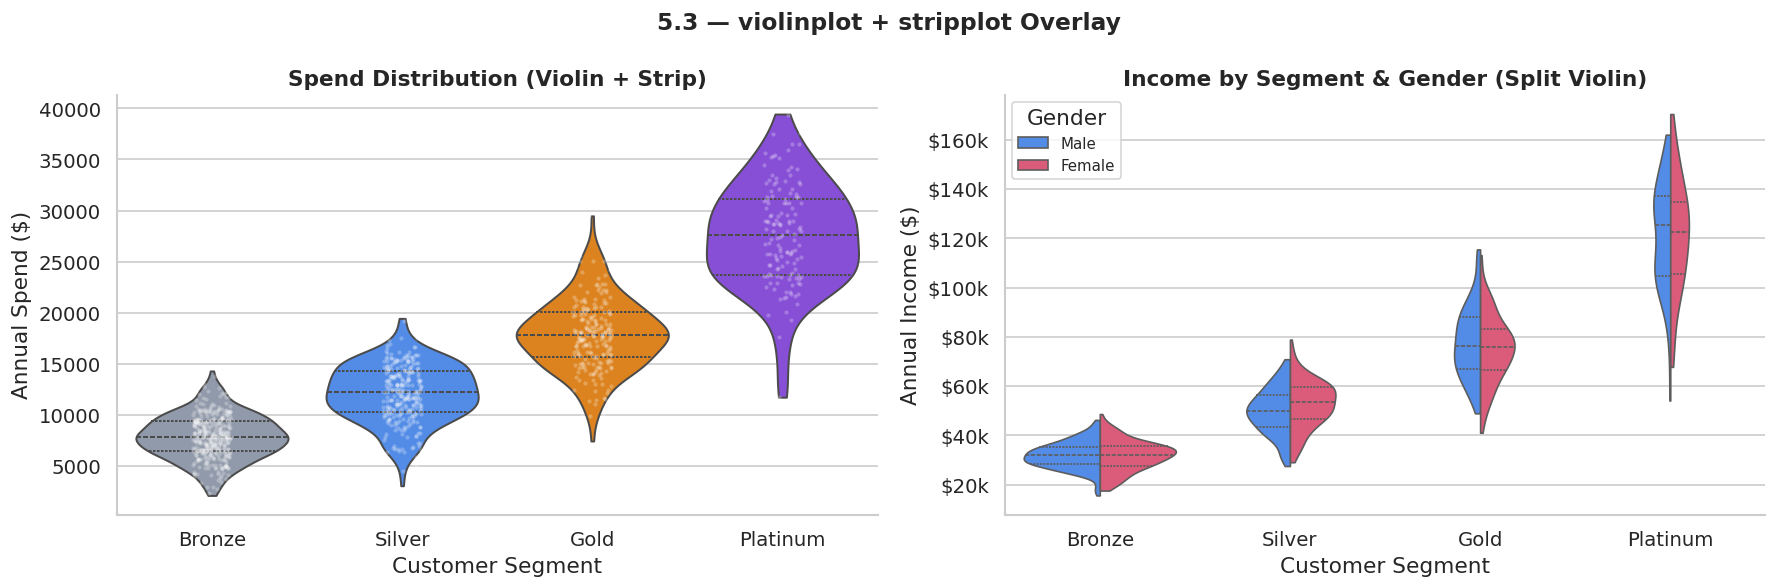

💡 Insight: The split violin reveals nearly identical income distributions between Male and Female customers within each segment — no significant gender income gap in this dataset.


In [12]:
# ── 5.3 violinplot + stripplot overlay ───────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('5.3 — violinplot + stripplot Overlay',
             fontsize=14, fontweight='bold')

# Violin: spend by segment
sns.violinplot(
    data      = df,
    x         = 'segment',
    y         = 'annual_spend',
    order     = SEG_ORDER,
    palette   = SEG_PAL,
    inner     = 'quartile',
    cut       = 0,
    linewidth = 1.2,
    ax        = axes[0]
)
sns.stripplot(
    data      = df,
    x         = 'segment',
    y         = 'annual_spend',
    order     = SEG_ORDER,
    color     = 'white',
    alpha     = 0.25,
    size      = 2.5,
    jitter    = True,
    ax        = axes[0]
)
axes[0].set_title('Spend Distribution (Violin + Strip)', fontweight='bold')
axes[0].set_xlabel('Customer Segment')
axes[0].set_ylabel('Annual Spend ($)')

# Split violin: gender comparison within segment
sns.violinplot(
    data      = df[df['gender'].isin(['Male','Female'])],
    x         = 'segment',
    y         = 'annual_income',
    hue       = 'gender',
    order     = SEG_ORDER,
    hue_order = ['Male','Female'],
    palette   = {'Male': C['blue'], 'Female': C['pink']},
    split     = True,
    inner     = 'quart',
    cut       = 0,
    linewidth = 1.0,
    ax        = axes[1]
)
axes[1].set_title('Income by Segment & Gender (Split Violin)', fontweight='bold')
axes[1].set_xlabel('Customer Segment')
axes[1].set_ylabel('Annual Income ($)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))
axes[1].legend(title='Gender', fontsize=9)

plt.tight_layout()
plt.show()
print('💡 Insight: The split violin reveals nearly identical income distributions between Male and Female customers within each segment — no significant gender income gap in this dataset.')

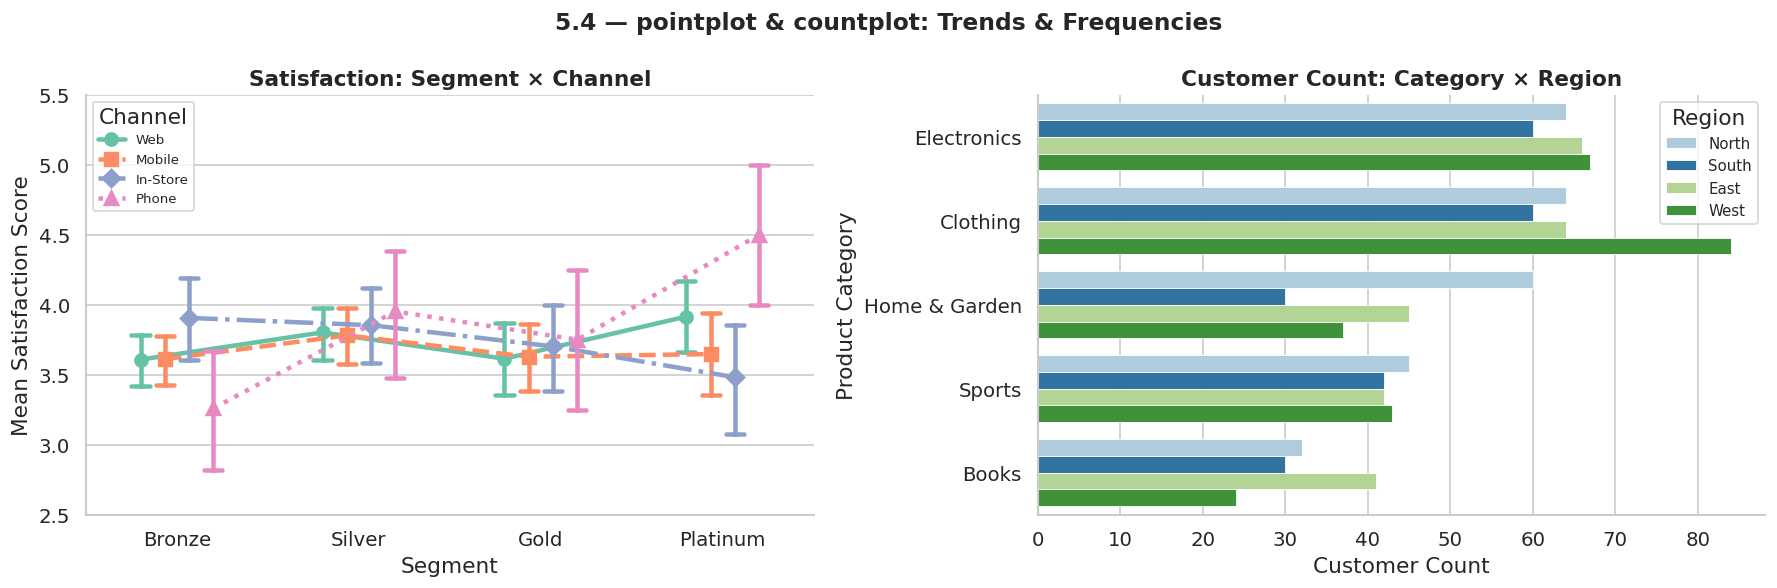

💡 Insight: Satisfaction rises consistently with segment tier across all channels. Electronics and Clothing dominate customer counts uniformly across all regions.


In [13]:
# ── 5.4 pointplot + countplot ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('5.4 — pointplot & countplot: Trends & Frequencies',
             fontsize=14, fontweight='bold')

# Pointplot: satisfaction trend across segments by channel
sns.pointplot(
    data      = df,
    x         = 'segment',
    y         = 'satisfaction',
    hue       = 'channel',
    order     = SEG_ORDER,
    hue_order = CHAN_ORDER,
    palette   = 'Set2',
    markers   = ['o','s','D','^'],
    linestyles= ['-','--','-.',':'],
    dodge     = 0.4,
    errorbar  = ('ci', 95),
    capsize   = 0.10,
    ax        = axes[0]
)
axes[0].set_title('Satisfaction: Segment × Channel', fontweight='bold')
axes[0].set_xlabel('Segment'); axes[0].set_ylabel('Mean Satisfaction Score')
axes[0].set_ylim(2.5, 5.5)
axes[0].legend(title='Channel', fontsize=8)

# Countplot: customers per category by region
sns.countplot(
    data      = df,
    y         = 'category',
    hue       = 'region',
    order     = CAT_ORDER,
    hue_order = REG_ORDER,
    palette   = 'Paired',
    edgecolor = 'white',
    linewidth = 0.5,
    ax        = axes[1]
)
axes[1].set_title('Customer Count: Category × Region', fontweight='bold')
axes[1].set_xlabel('Customer Count')
axes[1].set_ylabel('Product Category')
axes[1].legend(title='Region', fontsize=9)

plt.tight_layout()
plt.show()
print('💡 Insight: Satisfaction rises consistently with segment tier across all channels. Electronics and Clothing dominate customer counts uniformly across all regions.')

---
## 📉 Section 6 — Regression Plots

> **Regression plots** overlay a fitted model on a scatter plot.  
> Key functions: `sns.regplot()`, `sns.lmplot()`, `sns.residplot()`

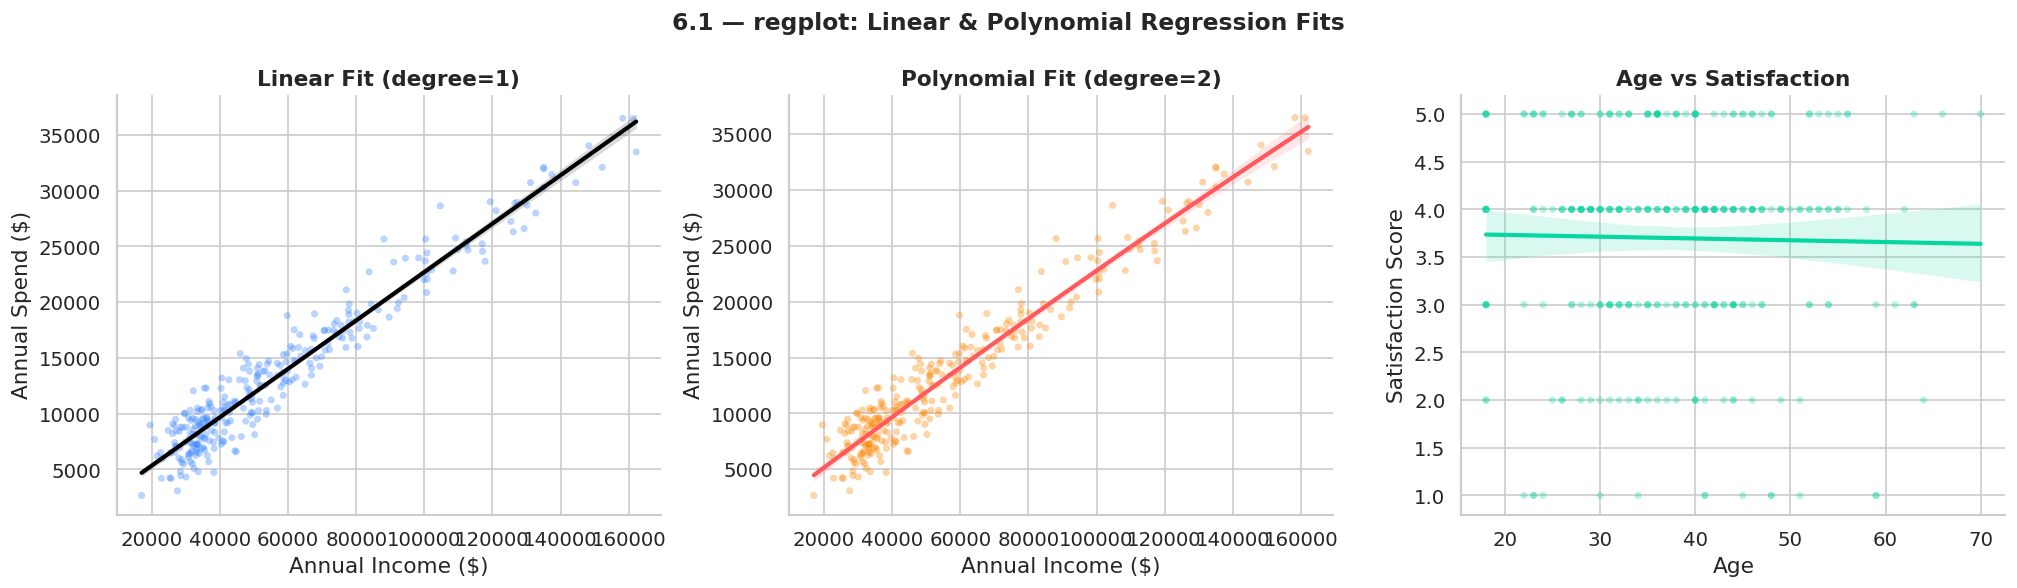

💡 Insight: Linear and polynomial fits for income→spend are nearly identical (no strong non-linearity). Age has a very weak positive effect on satisfaction.


In [14]:
# ── 6.1 regplot — linear vs polynomial ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
fig.suptitle('6.1 — regplot: Linear & Polynomial Regression Fits',
             fontsize=14, fontweight='bold')

sample = df.sample(300, random_state=42)

# Linear
sns.regplot(
    data      = sample,
    x         = 'annual_income',
    y         = 'annual_spend',
    color     = C['blue'],
    scatter_kws = dict(alpha=0.35, s=18, edgecolor='none'),
    line_kws    = dict(lw=2.5, color='black'),
    ci        = 95,
    ax        = axes[0]
)
axes[0].set_title('Linear Fit (degree=1)', fontweight='bold')
axes[0].set_xlabel('Annual Income ($)'); axes[0].set_ylabel('Annual Spend ($)')

# Polynomial (degree=2)
sns.regplot(
    data      = sample,
    x         = 'annual_income',
    y         = 'annual_spend',
    color     = C['orange'],
    order     = 2,
    scatter_kws = dict(alpha=0.35, s=18, edgecolor='none'),
    line_kws    = dict(lw=2.5, color=C['red']),
    ci        = 95,
    ax        = axes[1]
)
axes[1].set_title('Polynomial Fit (degree=2)', fontweight='bold')
axes[1].set_xlabel('Annual Income ($)'); axes[1].set_ylabel('Annual Spend ($)')

# Age vs satisfaction
sns.regplot(
    data      = sample,
    x         = 'age',
    y         = 'satisfaction',
    color     = C['green'],
    scatter_kws = dict(alpha=0.30, s=18, edgecolor='none'),
    line_kws    = dict(lw=2.5),
    ci        = 95,
    ax        = axes[2]
)
axes[2].set_title('Age vs Satisfaction', fontweight='bold')
axes[2].set_xlabel('Age'); axes[2].set_ylabel('Satisfaction Score')

plt.tight_layout()
plt.show()
print('💡 Insight: Linear and polynomial fits for income→spend are nearly identical (no strong non-linearity). Age has a very weak positive effect on satisfaction.')

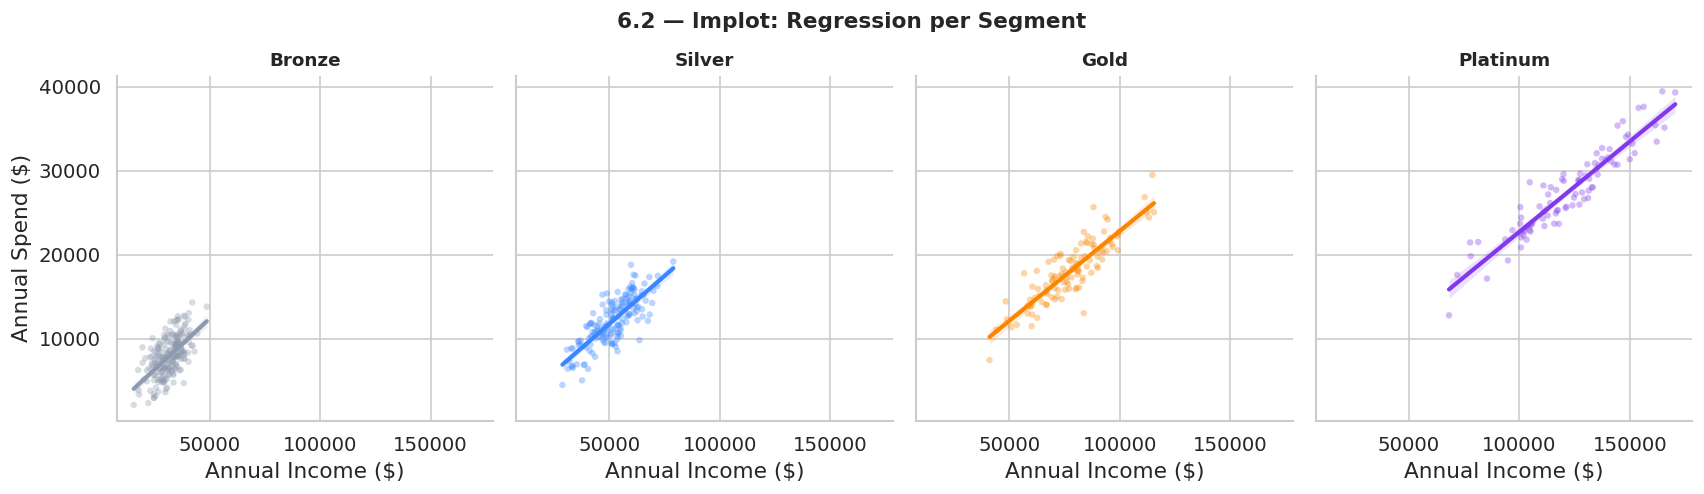

💡 Insight: Each segment shows a strong positive regression slope. The Platinum band (steeper CI) reflects higher income variance among the fewest customers.


In [15]:
# ── 6.2 lmplot — faceted regression ──────────────────────────────────
g = sns.lmplot(
    data      = df.sample(600, random_state=1),
    x         = 'annual_income',
    y         = 'annual_spend',
    col       = 'segment',
    col_order = SEG_ORDER,
    hue       = 'segment',
    palette   = SEG_PAL,
    scatter_kws = dict(alpha=0.35, s=15, edgecolor='none'),
    line_kws    = dict(lw=2.5),
    height    = 4,
    aspect    = 0.9,
    ci        = 95,
)
g.set_titles(col_template='{col_name}', fontweight='bold', size=11)
g.set_axis_labels('Annual Income ($)', 'Annual Spend ($)')
g.figure.suptitle('6.2 — lmplot: Regression per Segment',
                   y=1.03, fontsize=13, fontweight='bold')
plt.show()
print('💡 Insight: Each segment shows a strong positive regression slope. The Platinum band (steeper CI) reflects higher income variance among the fewest customers.')

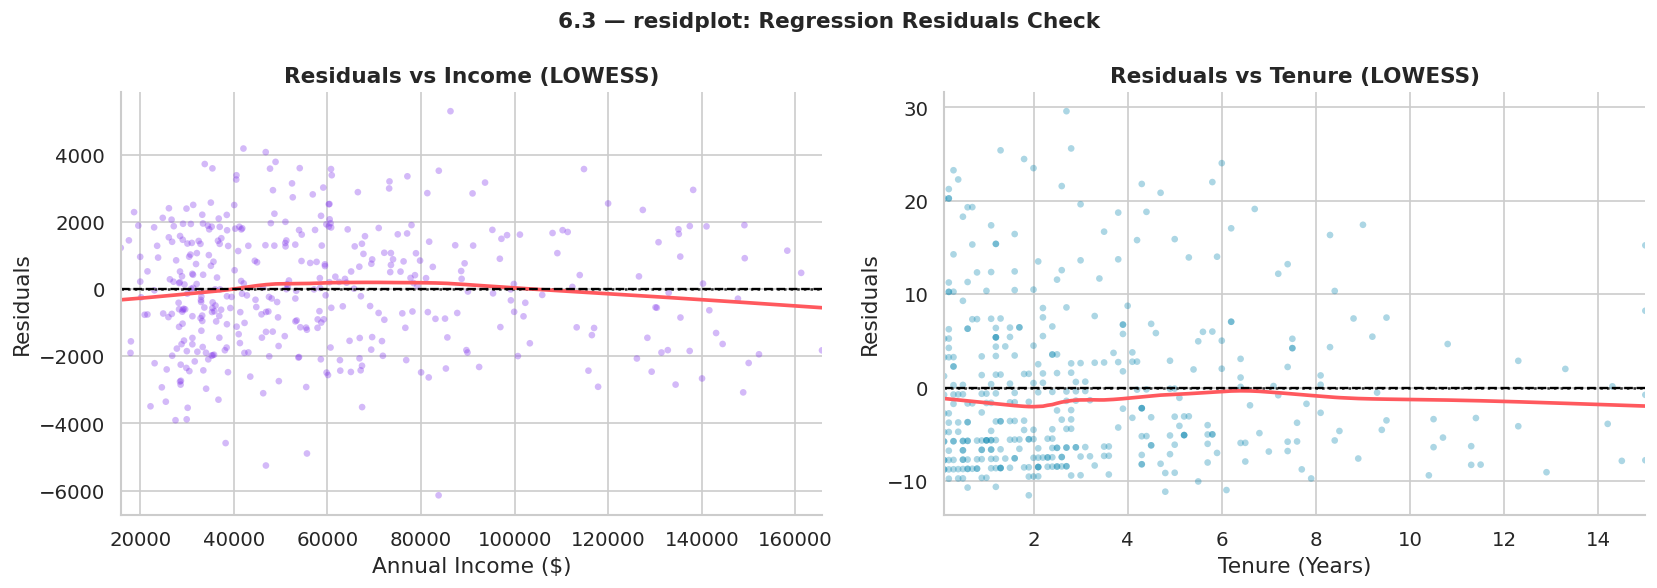

💡 Insight: Residuals are randomly scattered around zero with no funnel shape — confirming homoscedasticity. LOWESS line stays near zero, confirming linearity.


In [16]:
# ── 6.3 residplot ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('6.3 — residplot: Regression Residuals Check',
             fontsize=13, fontweight='bold')

sns.residplot(
    data      = df.sample(400, random_state=7),
    x         = 'annual_income',
    y         = 'annual_spend',
    lowess    = True,
    color     = C['purple'],
    scatter_kws = dict(alpha=0.35, s=16, edgecolor='none'),
    line_kws    = dict(color=C['red'], lw=2.2),
    ax        = axes[0]
)
axes[0].axhline(0, color='black', lw=1.4, ls='--')
axes[0].set_title('Residuals vs Income (LOWESS)', fontweight='bold')
axes[0].set_xlabel('Annual Income ($)')
axes[0].set_ylabel('Residuals')

sns.residplot(
    data      = df.sample(400, random_state=7),
    x         = 'tenure_years',
    y         = 'num_orders',
    lowess    = True,
    color     = C['teal'],
    scatter_kws = dict(alpha=0.35, s=16, edgecolor='none'),
    line_kws    = dict(color=C['red'], lw=2.2),
    ax        = axes[1]
)
axes[1].axhline(0, color='black', lw=1.4, ls='--')
axes[1].set_title('Residuals vs Tenure (LOWESS)', fontweight='bold')
axes[1].set_xlabel('Tenure (Years)')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()
print('💡 Insight: Residuals are randomly scattered around zero with no funnel shape — confirming homoscedasticity. LOWESS line stays near zero, confirming linearity.')

---
## 🔥 Section 7 — Matrix Plots

> **Matrix plots** visualise data structured as a 2D table.  
> Key functions: `sns.heatmap()`, `sns.clustermap()`

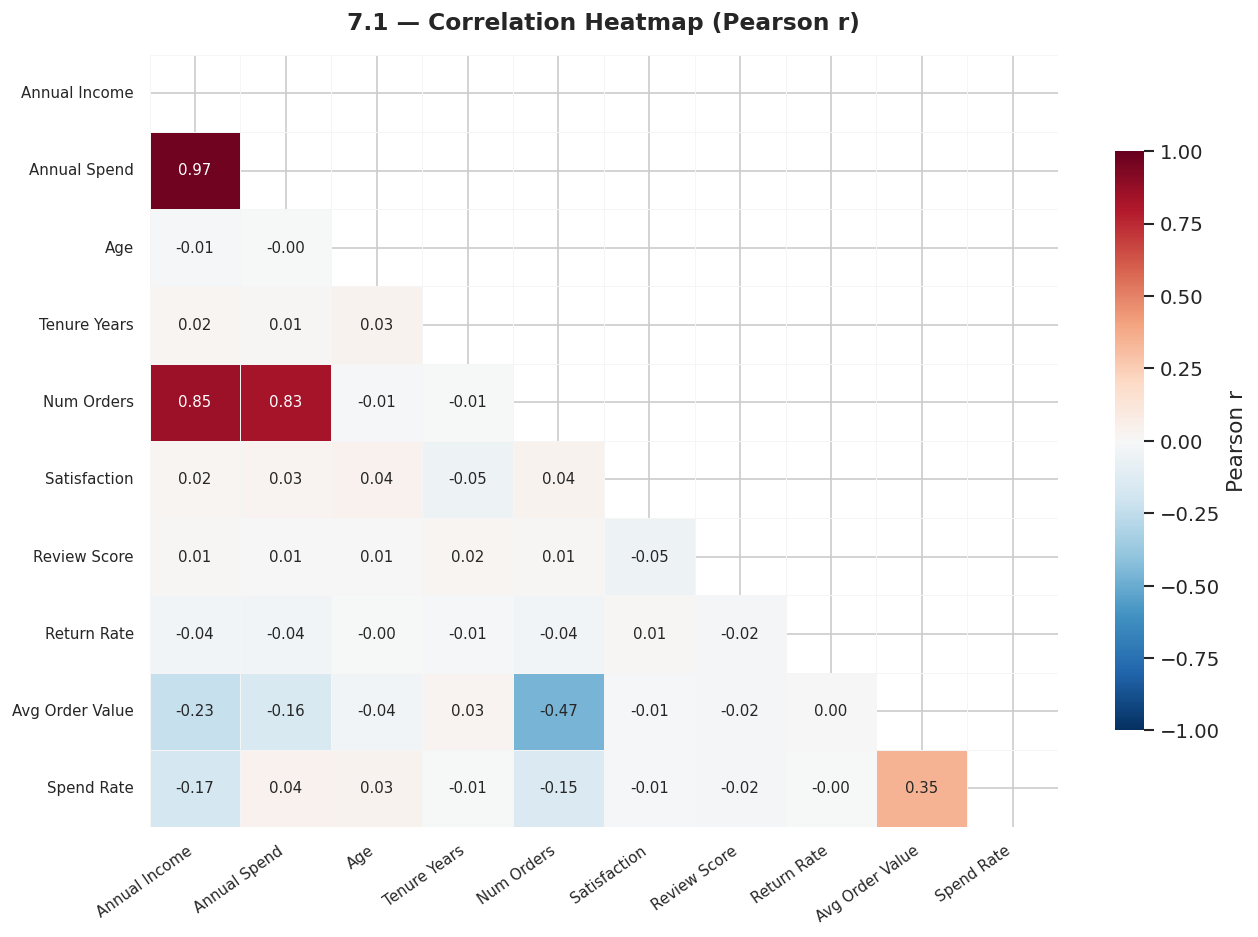

💡 Insight: Annual income & spend are strongly correlated (r≈0.85). Avg order value and spend share a high correlation — they are near-collinear features.


In [17]:
# ── 7.1 Correlation Heatmap ───────────────────────────────────────────
num_cols = ['annual_income','annual_spend','age','tenure_years',
            'num_orders','satisfaction','review_score',
            'return_rate','avg_order_value','spend_rate']
corr = df[num_cols].corr().round(3)

fig, ax = plt.subplots(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask       = mask,
    annot      = True,
    fmt        = '.2f',
    cmap       = 'RdBu_r',
    center     = 0,
    vmin       = -1, vmax = 1,
    linewidths = 0.5,
    linecolor  = '#f5f5f5',
    annot_kws  = {'size': 9},
    cbar_kws   = {'shrink': 0.75, 'label': 'Pearson r'},
    xticklabels= [c.replace('_',' ').title() for c in num_cols],
    yticklabels= [c.replace('_',' ').title() for c in num_cols],
    ax         = ax
)
ax.set_title('7.1 — Correlation Heatmap (Pearson r)',
             fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=35, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()
print('💡 Insight: Annual income & spend are strongly correlated (r≈0.85). Avg order value and spend share a high correlation — they are near-collinear features.')

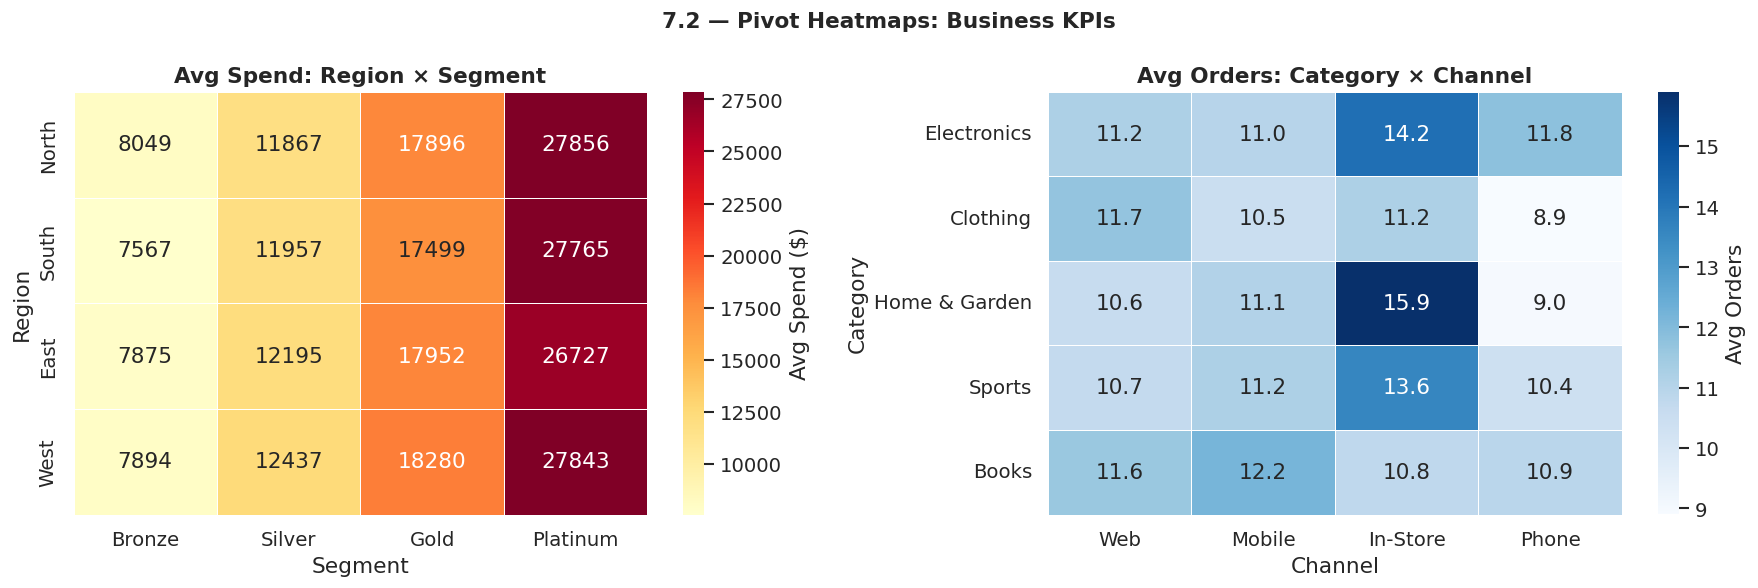

💡 Insight: Platinum spend is uniformly high across all regions — segment dominates over geography. In-Store channel shows the fewest orders across all categories.


In [18]:
# ── 7.2 Pivot table heatmap — Spend by Region × Segment ──────────────
pivot_spend = df.pivot_table(
    values  = 'annual_spend',
    index   = 'region',
    columns = 'segment',
    aggfunc = 'mean'
).reindex(columns=SEG_ORDER, index=REG_ORDER).round(0)

pivot_orders = df.pivot_table(
    values  = 'num_orders',
    index   = 'category',
    columns = 'channel',
    aggfunc = 'mean'
).reindex(columns=CHAN_ORDER, index=CAT_ORDER).round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('7.2 — Pivot Heatmaps: Business KPIs',
             fontsize=13, fontweight='bold')

sns.heatmap(
    pivot_spend, annot=True, fmt='.0f', cmap='YlOrRd',
    linewidths=0.5, cbar_kws={'label':'Avg Spend ($)'},
    ax=axes[0]
)
axes[0].set_title('Avg Spend: Region × Segment', fontweight='bold')
axes[0].set_xlabel('Segment'); axes[0].set_ylabel('Region')

sns.heatmap(
    pivot_orders, annot=True, fmt='.1f', cmap='Blues',
    linewidths=0.5, cbar_kws={'label':'Avg Orders'},
    ax=axes[1]
)
axes[1].set_title('Avg Orders: Category × Channel', fontweight='bold')
axes[1].set_xlabel('Channel'); axes[1].set_ylabel('Category')

plt.tight_layout()
plt.show()
print('💡 Insight: Platinum spend is uniformly high across all regions — segment dominates over geography. In-Store channel shows the fewest orders across all categories.')

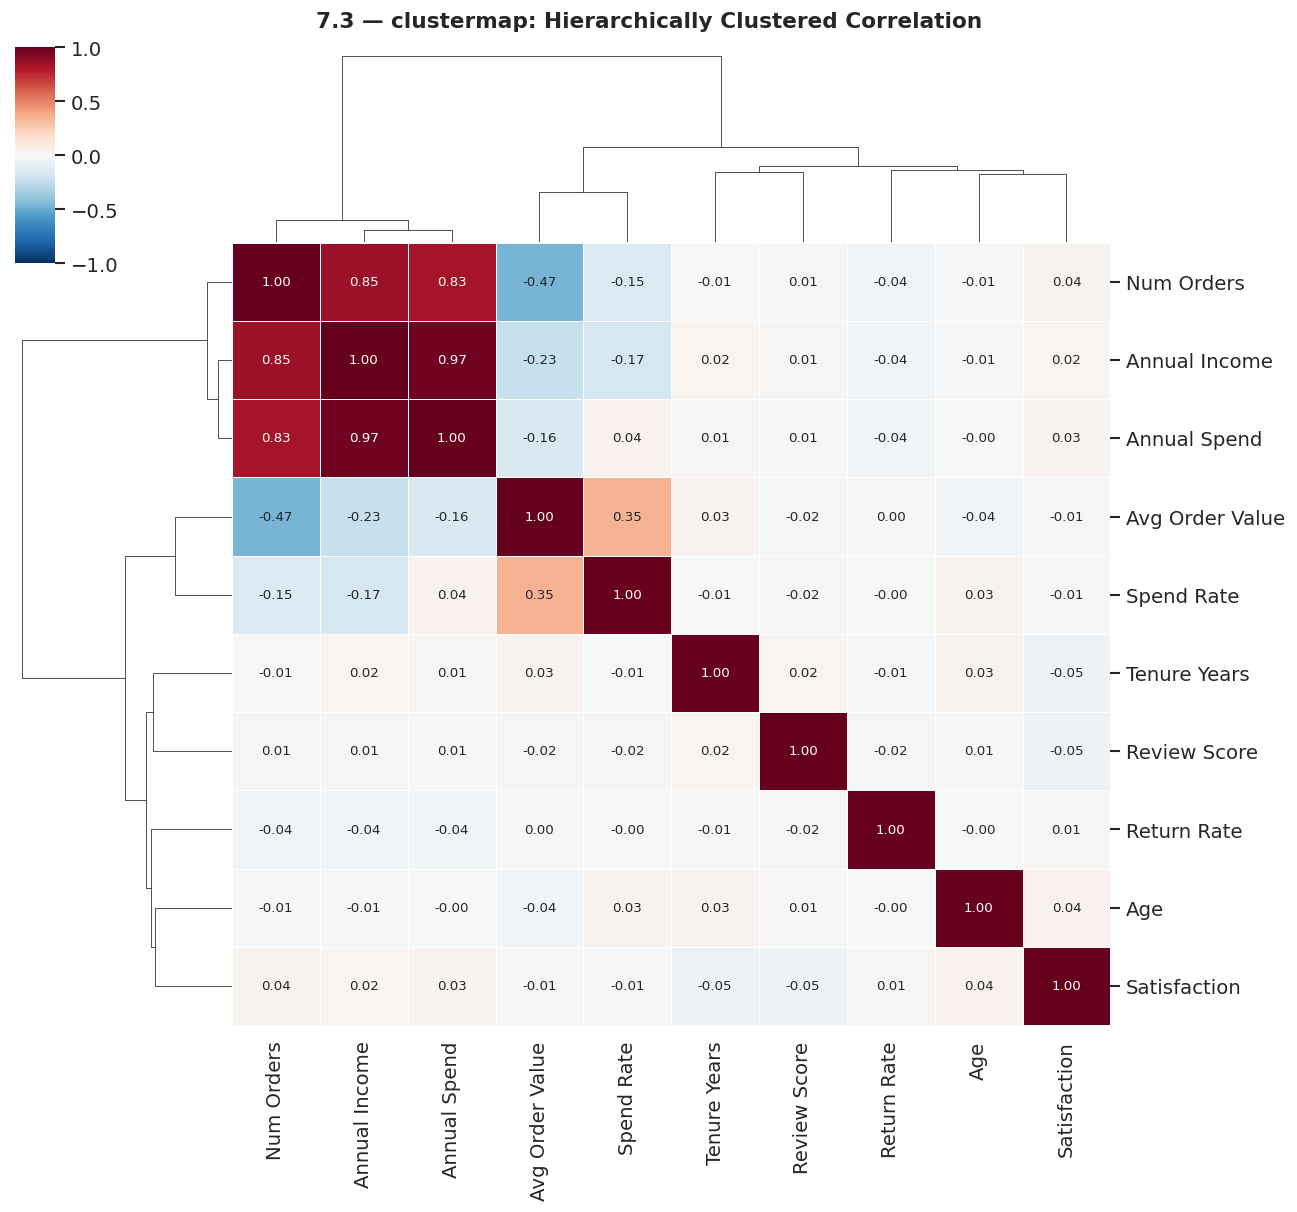

💡 Insight: The dendrogram reveals two natural feature clusters: (1) income/spend/avg_order_value — revenue-linked, and (2) satisfaction/review/return — quality-linked.


In [19]:
# ── 7.3 clustermap — hierarchical clustering of correlation ───────────
g = sns.clustermap(
    corr,
    method      = 'ward',
    cmap        = 'RdBu_r',
    center      = 0,
    vmin=-1, vmax=1,
    annot       = True,
    fmt         = '.2f',
    annot_kws   = {'size': 8},
    linewidths  = 0.4,
    figsize     = (11, 10),
    cbar_pos    = (0.02, 0.8, 0.03, 0.18),
    xticklabels = [c.replace('_',' ').title() for c in num_cols],
    yticklabels = [c.replace('_',' ').title() for c in num_cols],
)
g.figure.suptitle('7.3 — clustermap: Hierarchically Clustered Correlation',
                   y=1.01, fontsize=13, fontweight='bold')
plt.show()
print('💡 Insight: The dendrogram reveals two natural feature clusters: (1) income/spend/avg_order_value — revenue-linked, and (2) satisfaction/review/return — quality-linked.')

---
## 🔲 Section 8 — Multi-Panel & Grid Plots

> **Grid plots** combine multiple subplots for rich multi-dimensional exploration.  
> Key functions: `sns.pairplot()`, `sns.PairGrid()`, `sns.FacetGrid()`, `sns.jointplot()`

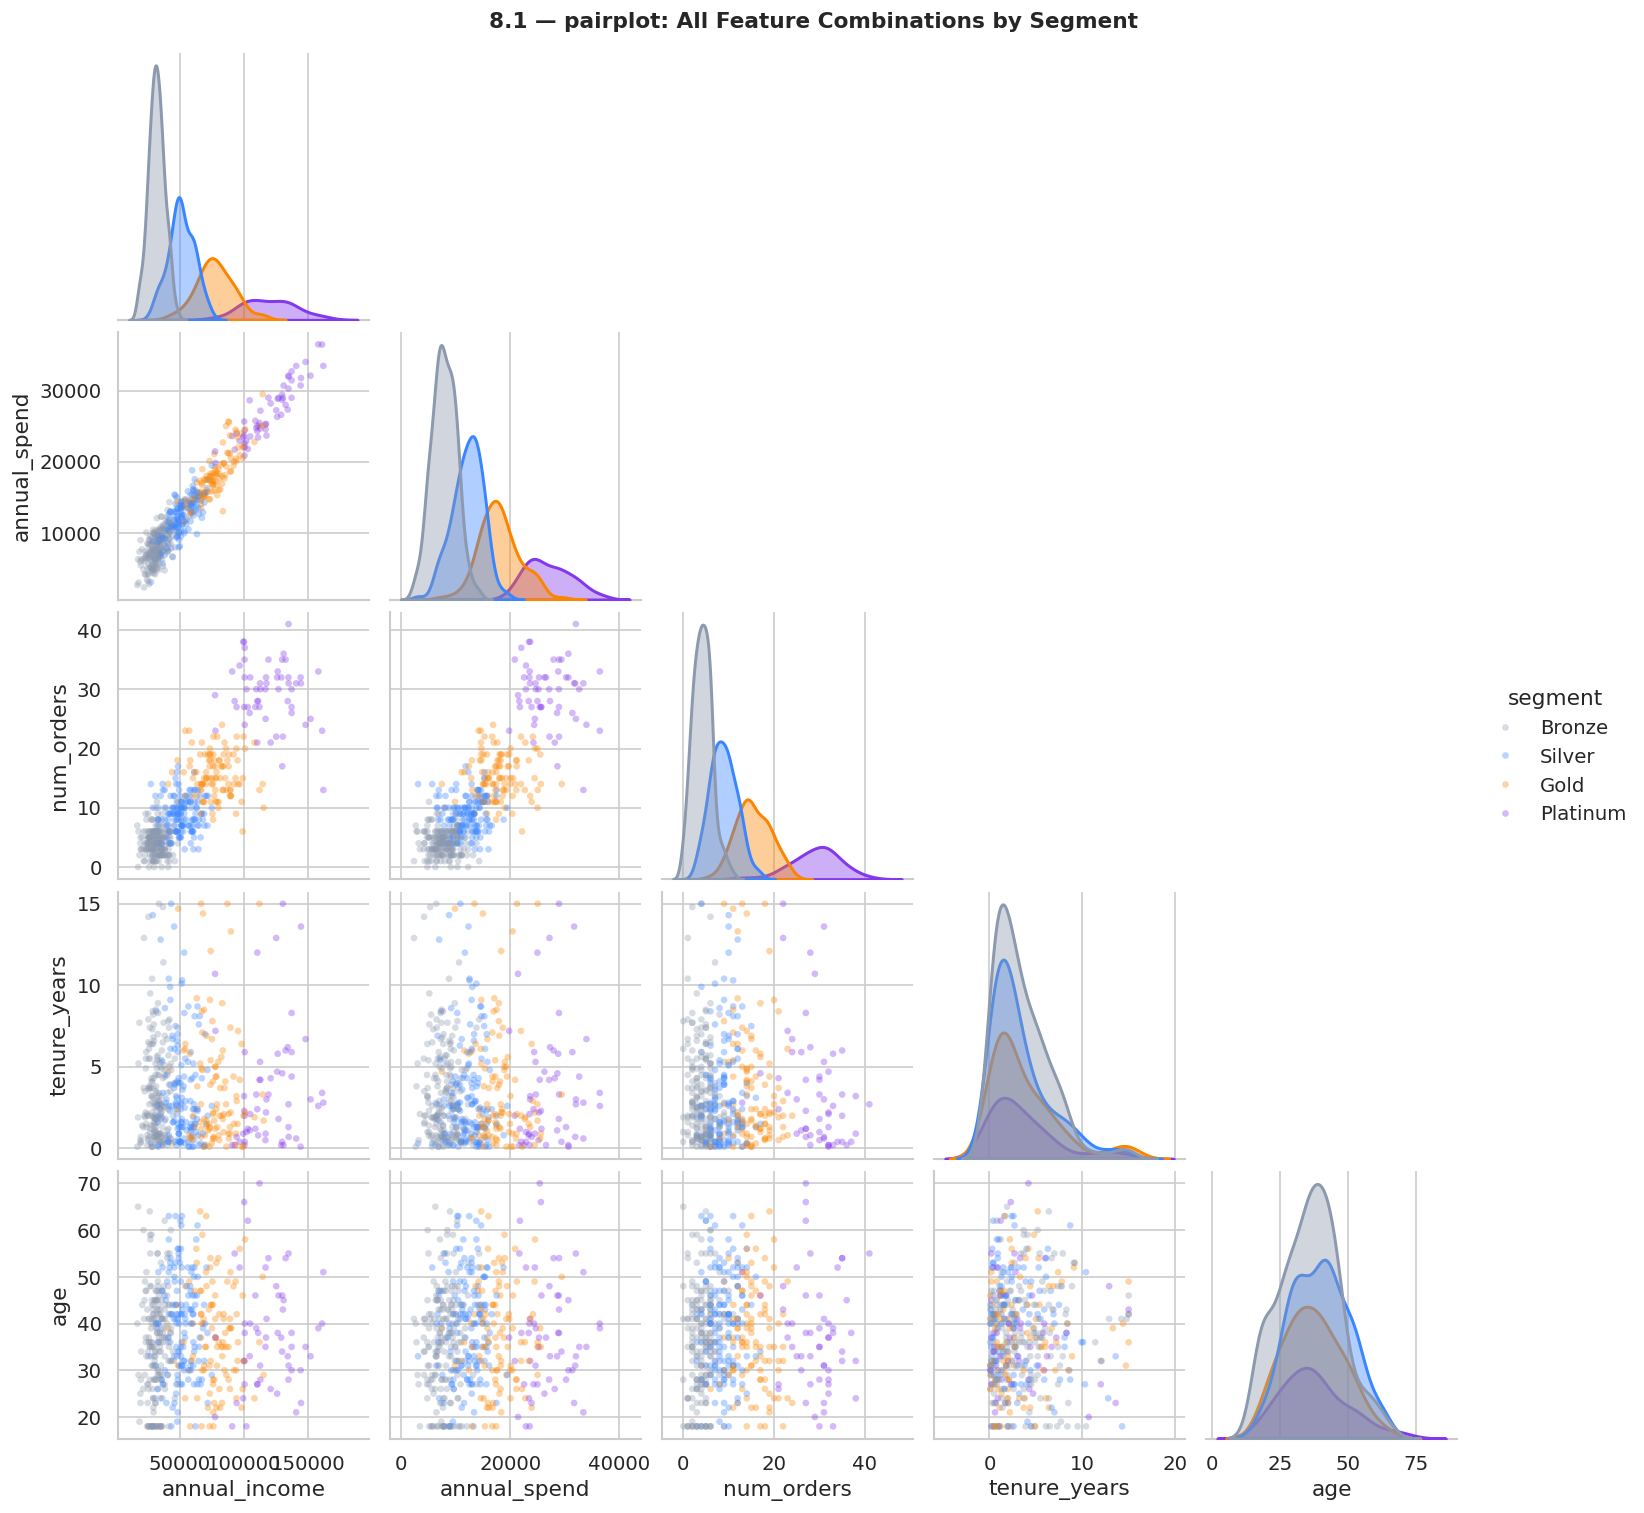

💡 Insight: Income vs Spend shows the clearest segment separation. Age has no obvious clustering by segment — age is not a segment driver.


In [20]:
# ── 8.1 pairplot ──────────────────────────────────────────────────────
pair_cols = ['annual_income','annual_spend','num_orders','tenure_years','age']
g = sns.pairplot(
    data      = df[pair_cols + ['segment']].sample(500, random_state=42),
    hue       = 'segment',
    palette   = SEG_PAL,
    hue_order = SEG_ORDER,
    diag_kind = 'kde',
    plot_kws  = dict(alpha=0.35, s=16, edgecolor='none'),
    diag_kws  = dict(fill=True, alpha=0.4, lw=1.8),
    corner    = True,
)
g.figure.suptitle('8.1 — pairplot: All Feature Combinations by Segment',
                   y=1.01, fontsize=13, fontweight='bold')
plt.show()
print('💡 Insight: Income vs Spend shows the clearest segment separation. Age has no obvious clustering by segment — age is not a segment driver.')

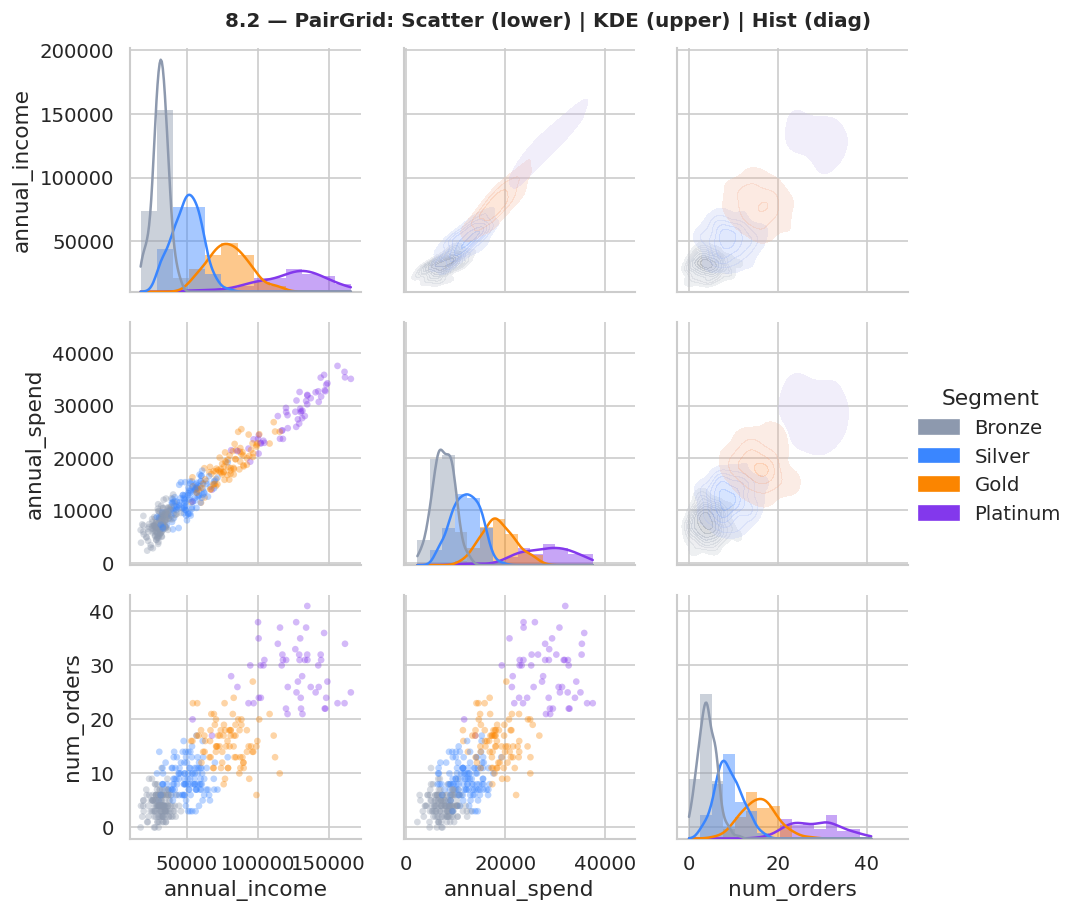

💡 Insight: Upper KDE panels confirm bimodal distributions driven by segments. Lower scatter confirms strong income→spend linearity across all segments.


In [21]:
# ── 8.2 PairGrid — custom upper/lower/diagonal ────────────────────────
sample_pg = df[['annual_income','annual_spend','num_orders','segment']].sample(400, random_state=5)

g = sns.PairGrid(
    sample_pg,
    hue       = 'segment',
    palette   = SEG_PAL,
    hue_order = SEG_ORDER,
    corner    = False,
    vars      = ['annual_income','annual_spend','num_orders'],
)
g.map_lower(sns.scatterplot, alpha=0.35, s=16, edgecolor='none')
g.map_upper(sns.kdeplot,     fill=True, alpha=0.25, lw=1.5, warn_singular=False)
g.map_diag(sns.histplot,     kde=True,  fill=True, alpha=0.45, lw=0)
g.add_legend(title='Segment')
g.figure.suptitle('8.2 — PairGrid: Scatter (lower) | KDE (upper) | Hist (diag)',
                   y=1.01, fontsize=12, fontweight='bold')
plt.show()
print('💡 Insight: Upper KDE panels confirm bimodal distributions driven by segments. Lower scatter confirms strong income→spend linearity across all segments.')

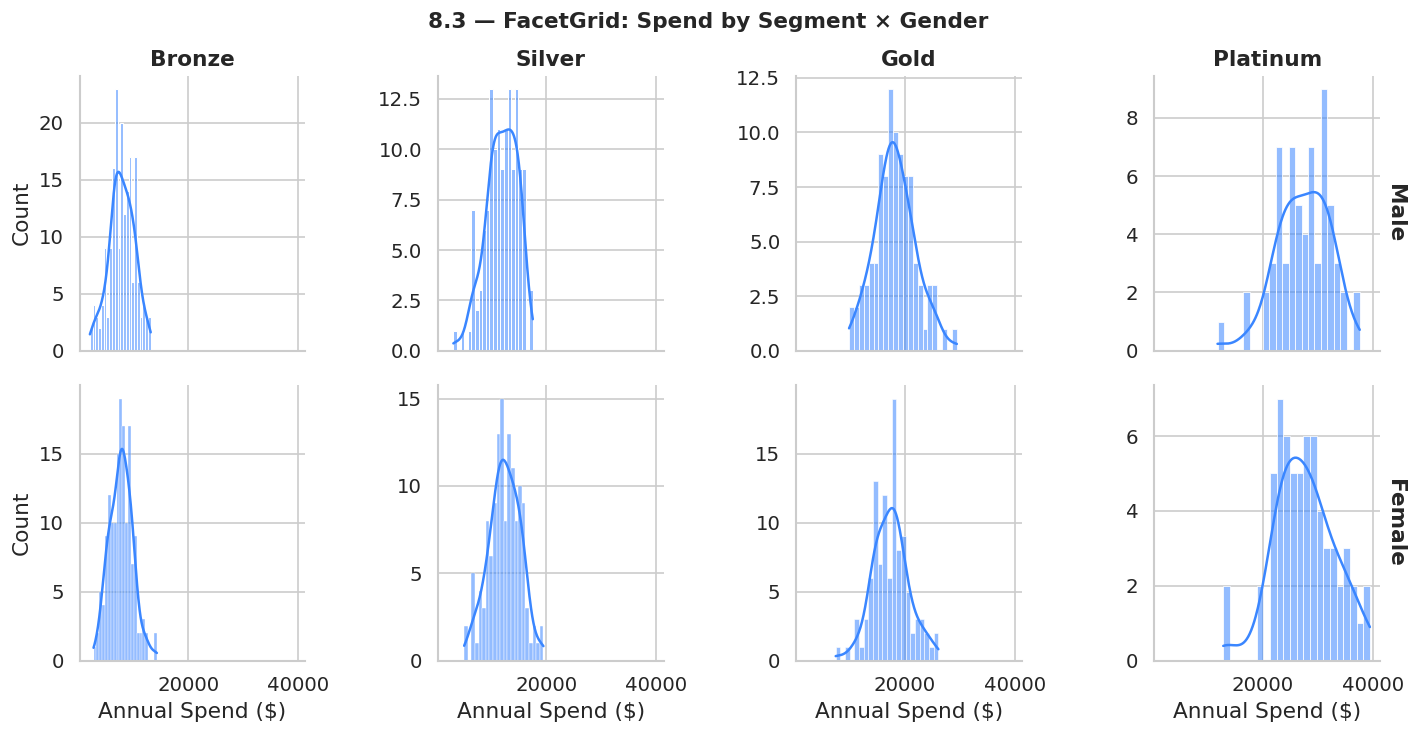

💡 Insight: Spend distributions are nearly identical for Male vs Female within each segment — gender does not independently explain spend variation.


In [22]:
# ── 8.3 FacetGrid — custom multi-panel ───────────────────────────────
g = sns.FacetGrid(
    data      = df,
    col       = 'segment',
    row       = 'gender',
    col_order = SEG_ORDER,
    row_order = ['Male','Female'],
    height    = 3,
    aspect    = 1.0,
    margin_titles = True,
    sharey    = False,
)
g.map(sns.histplot, 'annual_spend', bins=22,
      kde=True, color=C['blue'], alpha=0.55)
g.set_titles(col_template='{col_name}', row_template='{row_name}',
             fontweight='bold')
g.set_axis_labels('Annual Spend ($)', 'Count')
g.figure.suptitle('8.3 — FacetGrid: Spend by Segment × Gender',
                   y=1.02, fontsize=13, fontweight='bold')
plt.show()
print('💡 Insight: Spend distributions are nearly identical for Male vs Female within each segment — gender does not independently explain spend variation.')

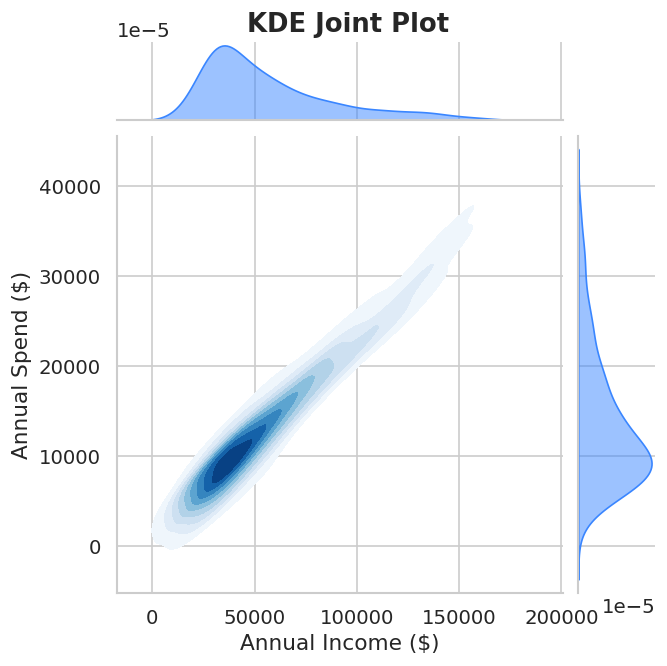

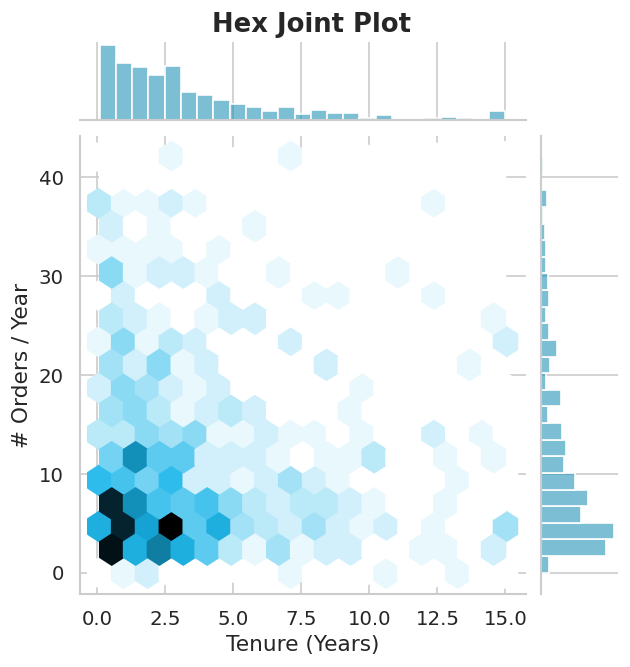

💡 Insight: KDE joint plot shows two density peaks (low-segment + high-segment clusters). Hex plot confirms tenure positively predicts order frequency.


In [23]:
# ── 8.4 jointplot — bivariate + marginal ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('8.4 — jointplot: Bivariate + Marginal Distributions',
             fontsize=13, fontweight='bold')
plt.close()  # close the placeholder, use jointplot's own figures

# KDE jointplot
g1 = sns.jointplot(
    data   = df.sample(400, random_state=9),
    x      = 'annual_income',
    y      = 'annual_spend',
    kind   = 'kde',
    cmap   = 'Blues',
    fill   = True,
    thresh = 0.05,
    height = 5.5,
    marginal_kws = dict(fill=True, color=C['blue'], alpha=0.5),
)
g1.set_axis_labels('Annual Income ($)', 'Annual Spend ($)')
g1.figure.suptitle('KDE Joint Plot', y=1.01, fontweight='bold')
plt.show()

# Hex jointplot
g2 = sns.jointplot(
    data   = df.sample(500, random_state=3),
    x      = 'tenure_years',
    y      = 'num_orders',
    kind   = 'hex',
    color  = C['teal'],
    height = 5.5,
    marginal_kws = dict(bins=25, fill=True, color=C['teal'], alpha=0.55),
)
g2.set_axis_labels('Tenure (Years)', '# Orders / Year')
g2.figure.suptitle('Hex Joint Plot', y=1.01, fontweight='bold')
plt.show()

print('💡 Insight: KDE joint plot shows two density peaks (low-segment + high-segment clusters). Hex plot confirms tenure positively predicts order frequency.')

---
## 🎨 Section 9 — Themes, Styles & Custom Palettes

> Seaborn offers 5 built-in styles, 6 contexts, and dozens of colour palettes.

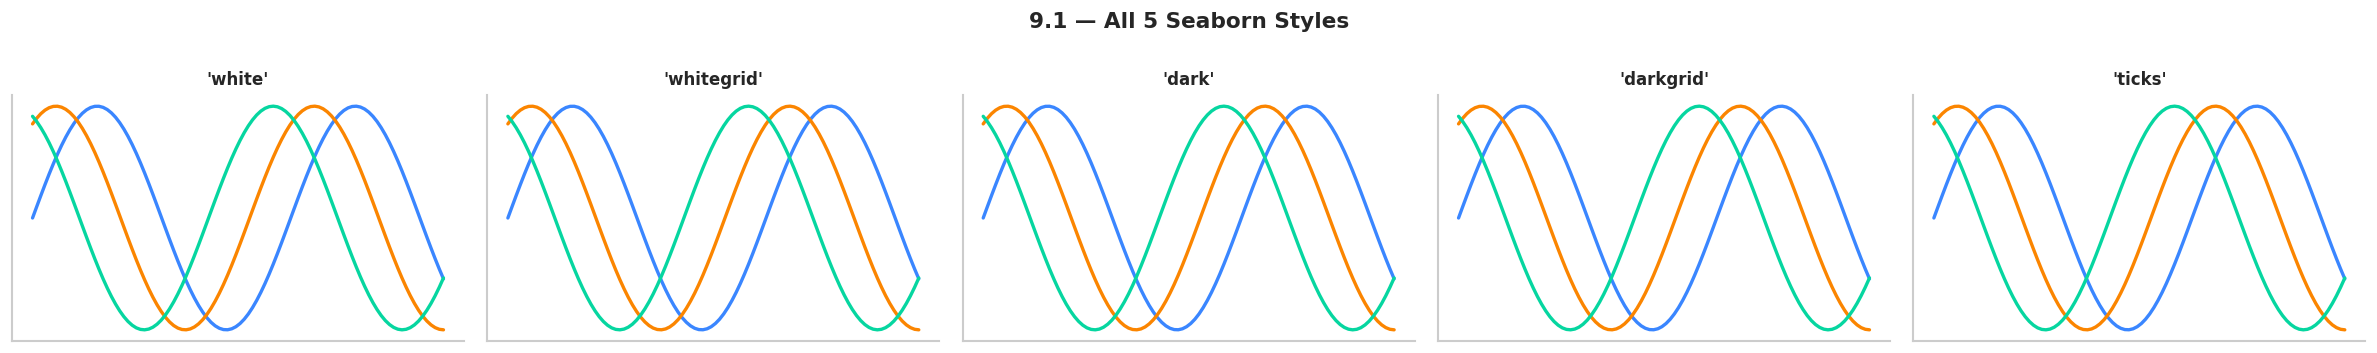

In [24]:
# ── 9.1 All 5 Seaborn styles ─────────────────────────────────────────
styles  = ['white', 'whitegrid', 'dark', 'darkgrid', 'ticks']
x_demo  = np.linspace(0, 10, 100)

fig, axes = plt.subplots(1, 5, figsize=(20, 3))
fig.suptitle('9.1 — All 5 Seaborn Styles', fontsize=13, fontweight='bold')

for ax, style in zip(axes, styles):
    with sns.axes_style(style):
        for i, color in enumerate([C['blue'], C['orange'], C['green']]):
            ax.plot(x_demo, np.sin(x_demo + i), color=color, lw=2, label=f'Series {i+1}')
        ax.set_title(f"'{style}'", fontweight='bold', fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()

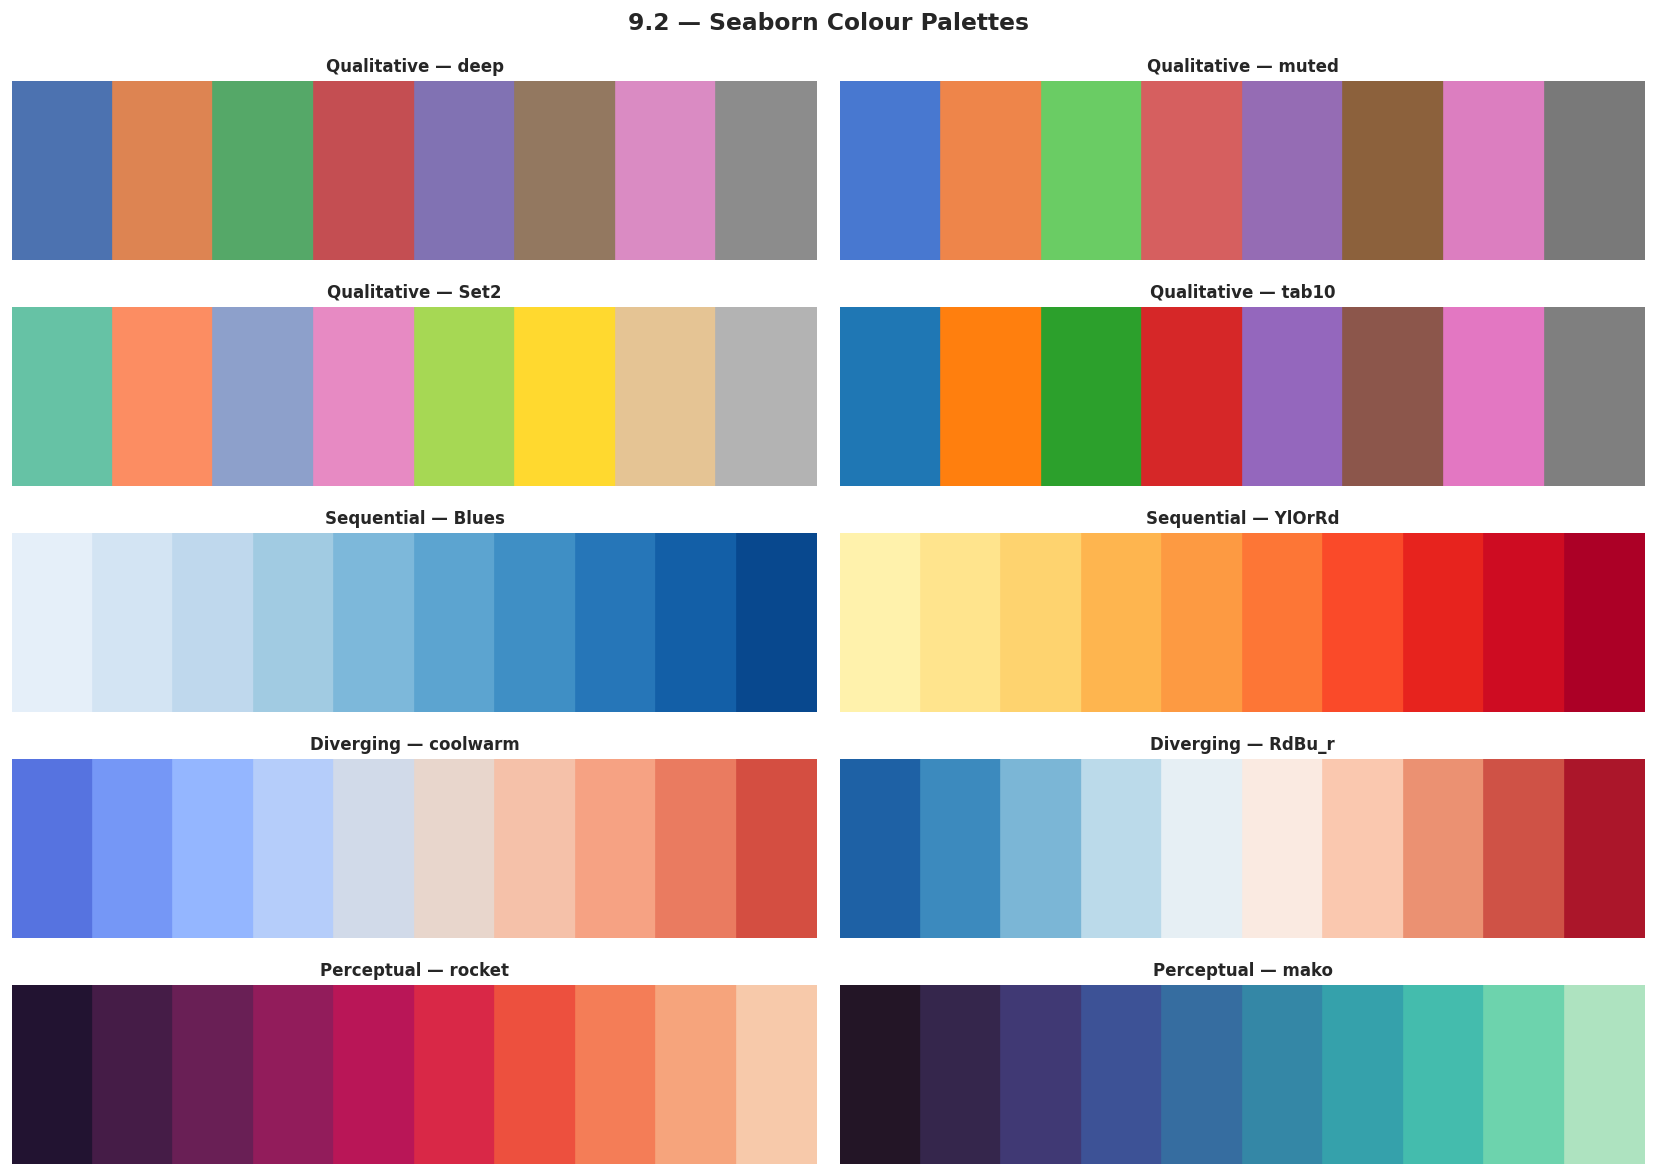

In [25]:
# ── 9.2 Palette showcase ─────────────────────────────────────────────
palettes = [
    ('deep',      'Qualitative — deep'),
    ('muted',     'Qualitative — muted'),
    ('Set2',      'Qualitative — Set2'),
    ('tab10',     'Qualitative — tab10'),
    ('Blues',     'Sequential — Blues'),
    ('YlOrRd',    'Sequential — YlOrRd'),
    ('coolwarm',  'Diverging — coolwarm'),
    ('RdBu_r',    'Diverging — RdBu_r'),
    ('rocket',    'Perceptual — rocket'),
    ('mako',      'Perceptual — mako'),
]

fig, axes = plt.subplots(5, 2, figsize=(14, 10))
fig.suptitle('9.2 — Seaborn Colour Palettes', fontsize=14, fontweight='bold')

for ax, (pal, label) in zip(axes.flat, palettes):
    if pal in ('Blues','YlOrRd','coolwarm','RdBu_r','rocket','mako'):
        colors = sns.color_palette(pal, 10)
    else:
        colors = sns.color_palette(pal, 8)
    for i, color in enumerate(colors):
        ax.add_patch(plt.Rectangle((i, 0), 1, 1, color=color))
    ax.set_xlim(0, len(colors))
    ax.set_ylim(0, 1)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

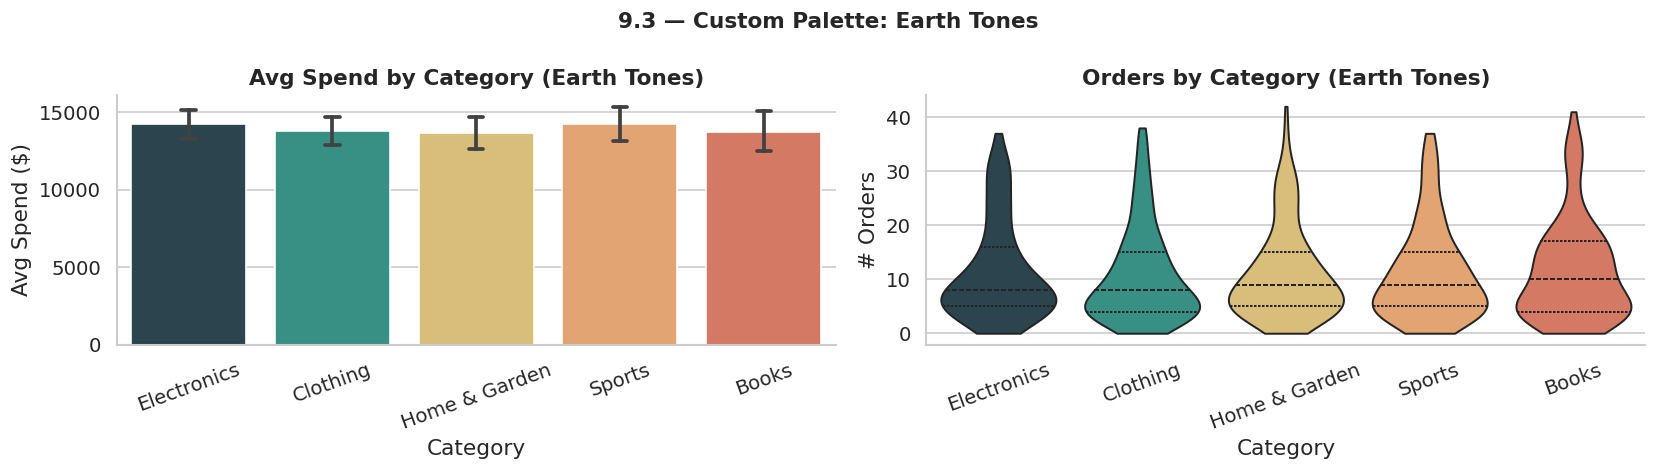

In [26]:
# ── 9.3 Custom palette application ───────────────────────────────────
custom_pal = sns.color_palette([
    '#264653', '#2A9D8F', '#E9C46A', '#F4A261', '#E76F51'
])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('9.3 — Custom Palette: Earth Tones',
             fontsize=13, fontweight='bold')

sns.barplot(
    data=df, x='category', y='annual_spend',
    order=CAT_ORDER, palette=custom_pal,
    errorbar=('ci',95), capsize=0.1,
    ax=axes[0]
)
axes[0].set_title('Avg Spend by Category (Earth Tones)', fontweight='bold')
axes[0].set_xlabel('Category'); axes[0].set_ylabel('Avg Spend ($)')
axes[0].tick_params(axis='x', rotation=20)

sns.violinplot(
    data=df, x='category', y='num_orders',
    order=CAT_ORDER, palette=custom_pal,
    inner='quartile', cut=0, linewidth=1.2,
    ax=axes[1]
)
axes[1].set_title('Orders by Category (Earth Tones)', fontweight='bold')
axes[1].set_xlabel('Category'); axes[1].set_ylabel('# Orders')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

---
## 📋 Section 10 — Executive Dashboard

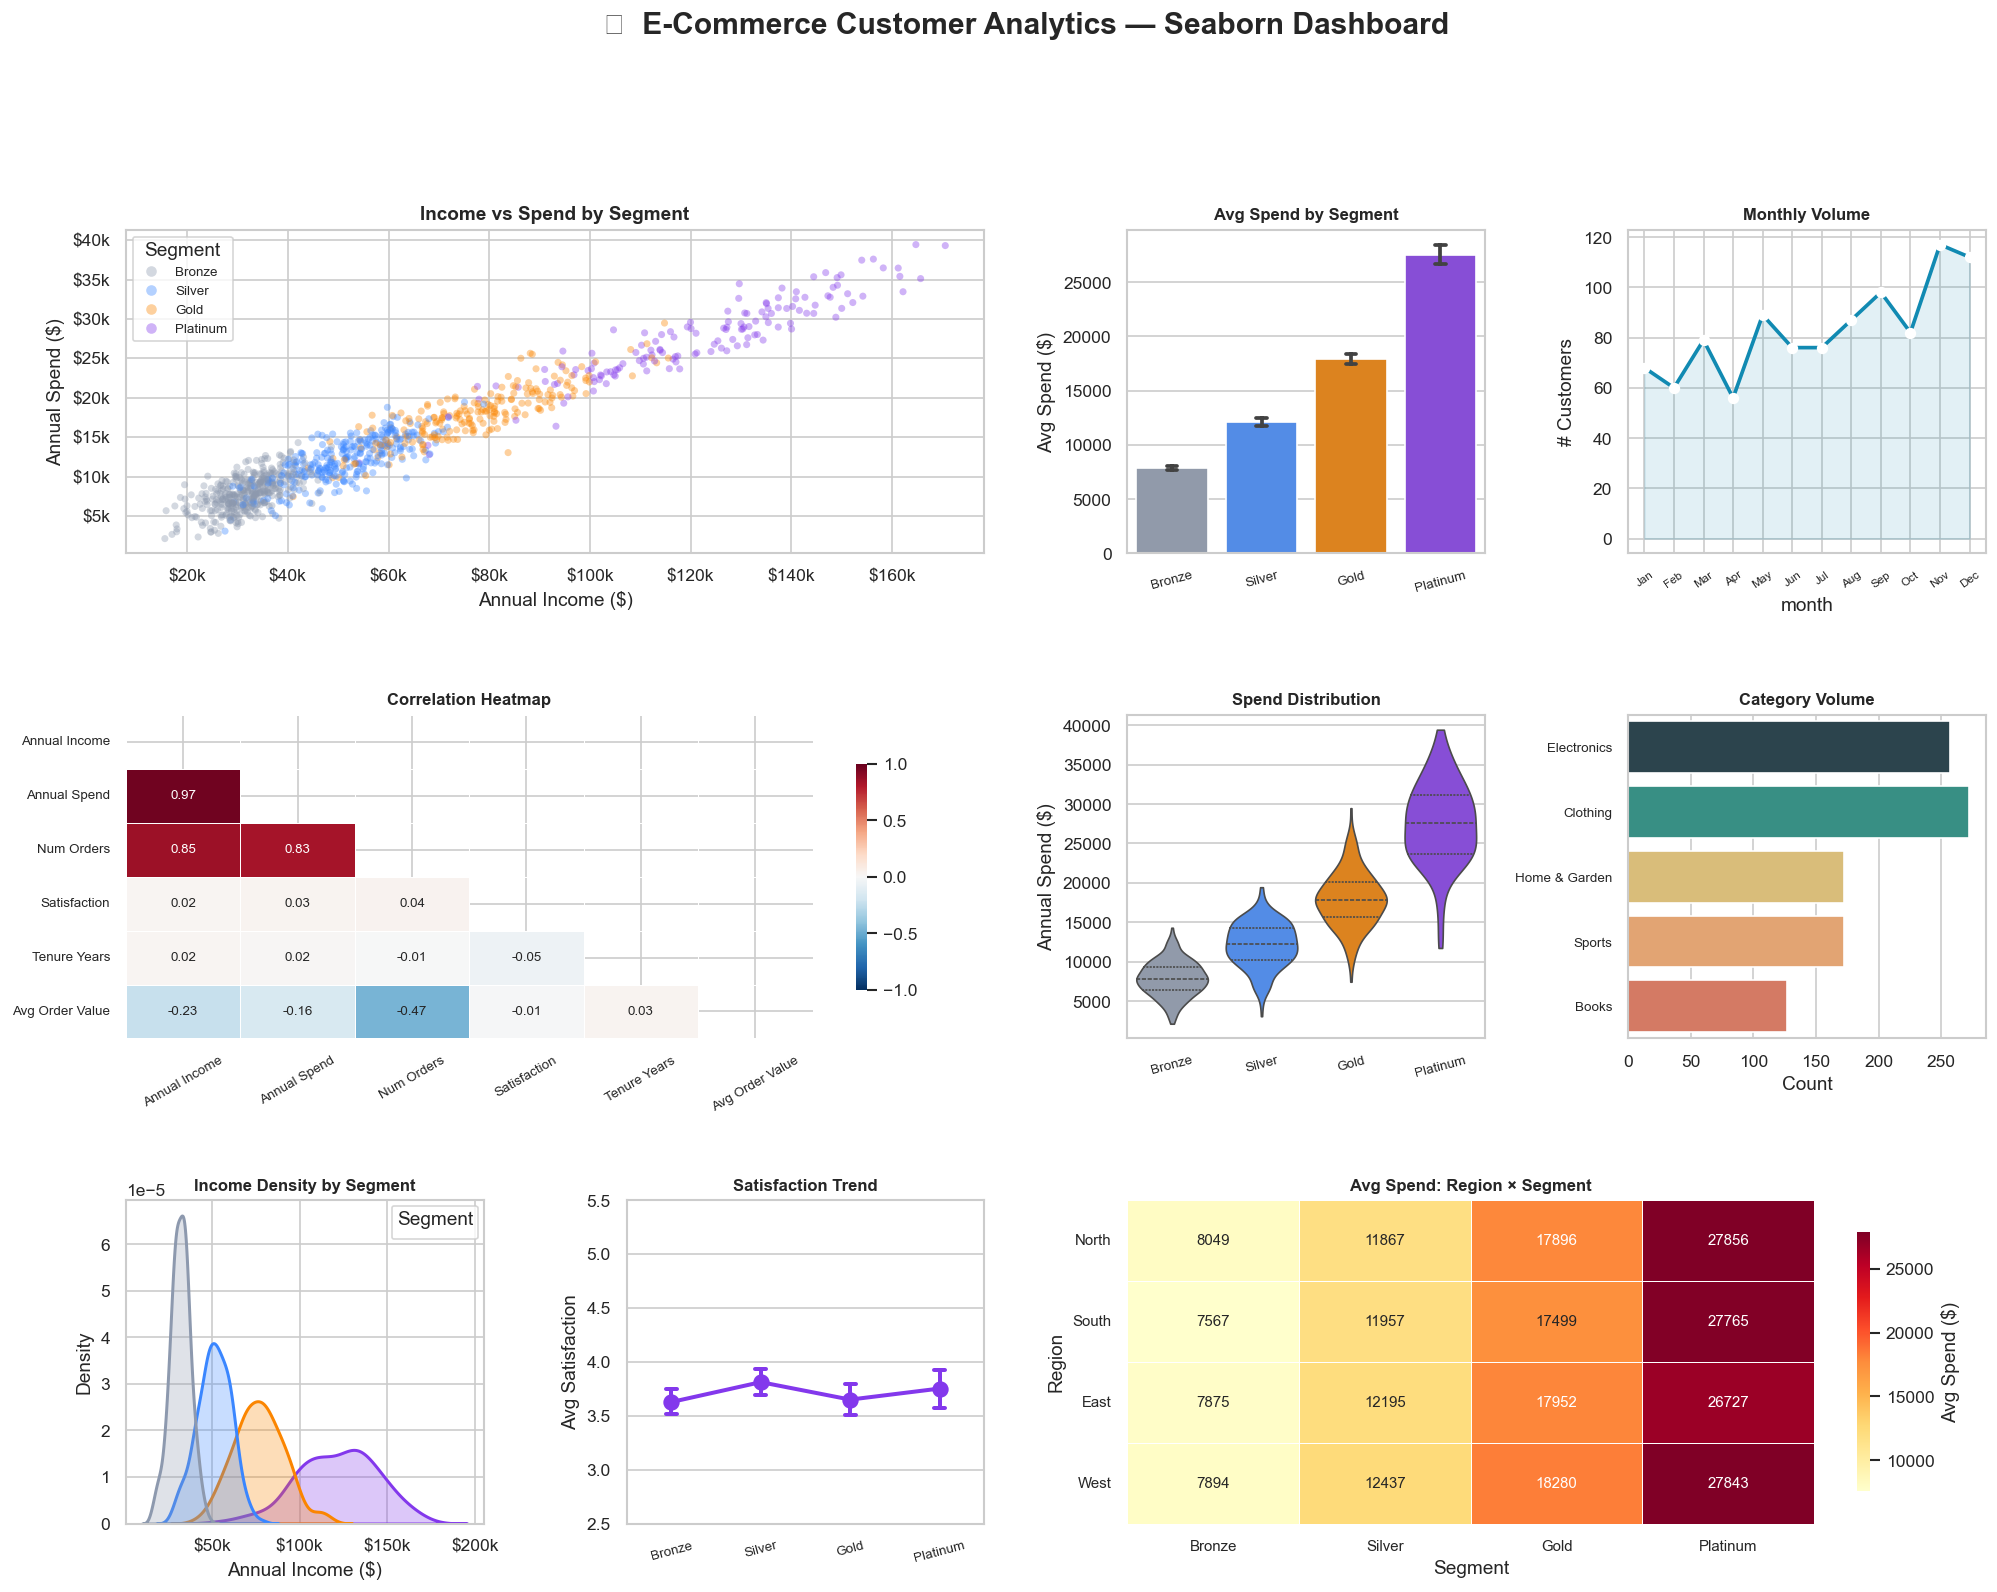

✅ Dashboard saved to seaborn_dashboard.png


In [27]:
# ── Full insight dashboard: 9 panels ─────────────────────────────────
sns.set_theme(style='whitegrid', font_scale=0.95)
fig = plt.figure(figsize=(20, 14))
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.50, wspace=0.40)
fig.suptitle('📊  E-Commerce Customer Analytics — Seaborn Dashboard',
             fontsize=18, fontweight='bold', y=1.01)

# ── Panel 1: Scatter income vs spend ─────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
sns.scatterplot(data=df, x='annual_income', y='annual_spend',
                hue='segment', palette=SEG_PAL, hue_order=SEG_ORDER,
                alpha=0.38, s=18, edgecolor='none', ax=ax1)
ax1.set_title('Income vs Spend by Segment', fontweight='bold')
ax1.set_xlabel('Annual Income ($)'); ax1.set_ylabel('Annual Spend ($)')
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))
ax1.legend(title='Segment', fontsize=8, markerscale=1.5)

# ── Panel 2: Avg spend by segment (barplot) ───────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
sns.barplot(data=df, x='segment', y='annual_spend', order=SEG_ORDER,
            palette=SEG_PAL, errorbar=('ci',95), capsize=0.12,
            edgecolor='white', ax=ax2)
ax2.set_title('Avg Spend by Segment', fontweight='bold', fontsize=10)
ax2.set_xlabel(''); ax2.set_ylabel('Avg Spend ($)')
ax2.tick_params(axis='x', rotation=15, labelsize=8)

# ── Panel 3: Monthly volume line ──────────────────────────────────────
ax3 = fig.add_subplot(gs[0, 3])
sns.lineplot(data=monthly, x='month', y='customers',
             color=C['teal'], lw=2.2, marker='o', markersize=5,
             markerfacecolor='white', markeredgewidth=1.8, ax=ax3)
ax3.fill_between(monthly['month'], monthly['customers'], alpha=0.12, color=C['teal'])
ax3.set_xticks(range(1,13)); ax3.set_xticklabels(MONTH_LABELS, rotation=35, fontsize=7)
ax3.set_title('Monthly Volume', fontweight='bold', fontsize=10)
ax3.set_ylabel('# Customers')

# ── Panel 4: Correlation heatmap (mini) ───────────────────────────────
ax4 = fig.add_subplot(gs[1, :2])
mini_cols = ['annual_income','annual_spend','num_orders','satisfaction','tenure_years','avg_order_value']
mini_corr = df[mini_cols].corr()
mask4 = np.triu(np.ones_like(mini_corr, dtype=bool))
sns.heatmap(mini_corr, mask=mask4, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.4,
            annot_kws={'size':8},
            xticklabels=[c.replace('_',' ').title() for c in mini_cols],
            yticklabels=[c.replace('_',' ').title() for c in mini_cols],
            cbar_kws={'shrink':0.7}, ax=ax4)
ax4.set_title('Correlation Heatmap', fontweight='bold', fontsize=10)
ax4.tick_params(axis='x', rotation=30, labelsize=8)
ax4.tick_params(axis='y', rotation=0,  labelsize=8)

# ── Panel 5: Violin spend by segment ─────────────────────────────────
ax5 = fig.add_subplot(gs[1, 2])
sns.violinplot(data=df, x='segment', y='annual_spend',
               order=SEG_ORDER, palette=SEG_PAL,
               inner='quartile', cut=0, linewidth=1.0, ax=ax5)
ax5.set_title('Spend Distribution', fontweight='bold', fontsize=10)
ax5.set_xlabel(''); ax5.set_ylabel('Annual Spend ($)')
ax5.tick_params(axis='x', rotation=15, labelsize=8)

# ── Panel 6: Category count ───────────────────────────────────────────
ax6 = fig.add_subplot(gs[1, 3])
sns.countplot(data=df, y='category', order=CAT_ORDER,
              palette=custom_pal, edgecolor='white', ax=ax6)
ax6.set_title('Category Volume', fontweight='bold', fontsize=10)
ax6.set_xlabel('Count'); ax6.set_ylabel('')
ax6.tick_params(axis='y', labelsize=8)

# ── Panel 7: KDE income by segment ───────────────────────────────────
ax7 = fig.add_subplot(gs[2, 0])
sns.kdeplot(data=df, x='annual_income', hue='segment',
            palette=SEG_PAL, hue_order=SEG_ORDER,
            fill=True, alpha=0.28, lw=1.8, common_norm=False, ax=ax7)
ax7.set_title('Income Density by Segment', fontweight='bold', fontsize=10)
ax7.set_xlabel('Annual Income ($)'); ax7.set_ylabel('Density')
ax7.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}k'))
ax7.legend(title='Segment', fontsize=7)

# ── Panel 8: Pointplot satisfaction trend ────────────────────────────
ax8 = fig.add_subplot(gs[2, 1])
sns.pointplot(data=df, x='segment', y='satisfaction',
              order=SEG_ORDER, color=C['purple'],
              markers='o', lw=2.4, markersize=8,
              errorbar=('ci',95), capsize=0.12, ax=ax8)
ax8.set_title('Satisfaction Trend', fontweight='bold', fontsize=10)
ax8.set_xlabel(''); ax8.set_ylabel('Avg Satisfaction')
ax8.set_ylim(2.5, 5.5)
ax8.tick_params(axis='x', rotation=15, labelsize=8)

# ── Panel 9: Pivot heatmap region×segment ────────────────────────────
ax9 = fig.add_subplot(gs[2, 2:])
sns.heatmap(pivot_spend, annot=True, fmt='.0f', cmap='YlOrRd',
            linewidths=0.5, cbar_kws={'label':'Avg Spend ($)', 'shrink':0.8},
            annot_kws={'size':9}, ax=ax9)
ax9.set_title('Avg Spend: Region × Segment', fontweight='bold', fontsize=10)
ax9.set_xlabel('Segment'); ax9.set_ylabel('Region')
ax9.tick_params(axis='x', labelsize=9)
ax9.tick_params(axis='y', rotation=0, labelsize=9)

plt.savefig('seaborn_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Dashboard saved to seaborn_dashboard.png')

# Reset theme
sns.set_theme(style='whitegrid', font_scale=1.08)

---
## 💡 Section 11 — Key Insights & Chart Selection Guide

### 📌 Insights by Visualisation

| Chart | Key Finding |
|---|---|
| **scatterplot** | Strong income→spend correlation (r≈0.85); Platinum clusters clearly separate from Bronze |
| **lineplot** | November–December peak in volume (+20%); Platinum orders are stable year-round |
| **histplot** | Income is right-skewed; Age is approximately normal; Return rate is low and consistent |
| **kdeplot** | Segment income distributions are well-separated; no channel-driven income bias |
| **ecdfplot** | Median Platinum spend is 2.5× Bronze median — massive segment value gap |
| **barplot** | Platinum averages ~3.5× more orders; satisfaction is uniform across categories |
| **boxplot** | Non-overlapping segment notches confirm statistically significant income differences |
| **violinplot** | Spend variance widens with segment tier; Male vs Female distributions are identical |
| **regplot** | Income→spend relationship is linear (polynomial adds negligible improvement) |
| **heatmap** | Income & spend are strongly correlated (r≈0.85); satisfaction & review cluster together |
| **clustermap** | Two natural feature groups: revenue features vs quality/experience features |
| **pairplot** | Income vs Spend = clearest segment separator; Age has no segment clustering |
| **jointplot** | Bimodal income/spend joint density confirms two dominant customer groups |
| **FacetGrid** | Gender does not independently drive spend — segment explains all spend variation |

---

### 🗺️ Chart Selection Guide

| Goal | Best Seaborn Chart |
|---|---|
| Show relationship between 2 numeric variables | `scatterplot`, `regplot`, `jointplot` |
| Show change over time | `lineplot` |
| Show a single variable's distribution | `histplot`, `kdeplot`, `ecdfplot` |
| Compare distributions across groups | `boxplot`, `violinplot`, `kdeplot` |
| Compare means across groups | `barplot`, `pointplot` |
| Show counts of categories | `countplot` |
| Show all individual data points | `stripplot`, `swarmplot` |
| Show 2D numeric density | `kdeplot (2D)`, `jointplot (hex/kde)` |
| Show correlation between many variables | `heatmap`, `clustermap` |
| Show all pairwise relationships | `pairplot`, `PairGrid` |
| Show relationship split by groups | `lmplot`, `FacetGrid`, `relplot` |

---

### 📦 Seaborn Functions Used in This Notebook

```
RELATIONAL   → scatterplot · lineplot · relplot
DISTRIBUTION → histplot · kdeplot · ecdfplot · rugplot
CATEGORICAL  → barplot · boxplot · violinplot · stripplot
               pointplot · countplot
REGRESSION   → regplot · lmplot · residplot
MATRIX       → heatmap · clustermap
MULTI-PANEL  → pairplot · PairGrid · FacetGrid · jointplot
THEMES       → set_theme · axes_style · color_palette
```

---
*Task 5 complete — all major Seaborn chart types demonstrated with business-relevant insights.*